# BraTS 2024 — 3D U-Net Training Pipeline
Optimized for Google Colab Free Tier (T4 GPU, ~15GB VRAM)  
4 Modalities: T1n, T1ce, T2f, T2w | 4 Classes: BG, NCR, Edema, ET

## Cell 1 — Install Dependencies
Installs all required Python packages. Run once at the start of each Colab session.

In [ ]:
!pip install nibabel -q
!pip install scikit-learn -q
!pip install tqdm -q
!pip install torchinfo -q
!pip install segmentation-models-pytorch -q
!pip install segmentation-models-pytorch-3d -q
!pip install torchmetrics -q
!pip install tensorboard -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 15.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 4.2 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.8/58.8 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.0/121.0 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 83.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 626.8/626.8 kB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 56.5 MB/s eta 0:00:00


In [ ]:
!pip install segmentation-models-pytorch -q

## Cell 2 — Mount Google Drive
Mounts Drive so checkpoints and preprocessed data persist across Colab sessions.
Without this, everything is lost on disconnect.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
DRIVE_BASE = '/content/drive/MyDrive/BraTS2024_3DUNet'
os.makedirs(DRIVE_BASE, exist_ok=True)
print(f"Drive base folder ready: {DRIVE_BASE}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive base folder ready: /content/drive/MyDrive/BraTS2024_3DUNet


## Cell 3 — Imports
Imports all libraries. Sets PYTORCH_ALLOC_CONF before torch import to prevent
CUDA memory fragmentation (fixes OOM errors on T4).

In [ ]:
import os
os.environ["PYTORCH_ALLOC_CONF"] = "expandable_segments:True"  # must be before torch import

import gc
import glob
import random
import shutil

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import nibabel as nib

from tqdm import tqdm
from dataclasses import dataclass
from sklearn.preprocessing import MinMaxScaler

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import Dataset, DataLoader
from torch.utils.tensorboard import SummaryWriter

from torchmetrics import MeanMetric
from torchmetrics.classification import MulticlassAccuracy

import segmentation_models_pytorch_3d as smp

print("All imports successful.")
print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    total_vram = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f"VRAM: {total_vram:.1f} GB")

All imports successful.
PyTorch: 2.10.0+cu128
CUDA available: True
GPU: Tesla T4
VRAM: 15.6 GB


## Cell 4 — Configuration
Central config dataclass. All hyperparameters and paths live here.
BATCH_SIZE=1 and GRAD_ACCUM_STEPS=8 gives effective batch of 8 while fitting in T4 VRAM.
CROP dimensions are carefully chosen so all axes produce exactly 128 voxels.

In [ ]:
@dataclass(frozen=True)
class Config:
    # Data paths
    DATASET_PATH:      str   = "/content/drive/MyDrive/Client_1_Hospital_A"
    PREPROCESSED_PATH: str   = "BraTS2024_Preprocessed"
    DRIVE_BASE:        str   = "/content/drive/MyDrive/BraTS2024_3DUNet"

    # Sampling
    NUM_FILES_TO_USE:  int   = 500
    RANDOM_SEED:       int   = 42
    TRAIN_RATIO:       float = 0.75

    # ROI crop — each axis: end - start = 128 exactly
    # BraTS volumes are (240, 240, 155)
    # X: 184 - 56 = 128
    # Y: 184 - 56 = 128
    # Z: 141 - 13 = 128
    CROP_X:            tuple = (56, 184)
    CROP_Y:            tuple = (56, 184)
    CROP_Z:            tuple = (13, 141)

    # Training — BATCH_SIZE=1 to fit T4 VRAM, GRAD_ACCUM=8 keeps effective batch=8
    BATCH_SIZE:        int   = 1
    EPOCHS:            int   = 50
    LEARNING_RATE:     float = 1e-3
    WEIGHT_DECAY:      float = 1e-2
    NUM_WORKERS:       int   = 2
    PIN_MEMORY:        bool  = True
    AMP_ENABLED:       bool  = True
    GRAD_ACCUM_STEPS:  int   = 8   # effective batch = 1 x 8 = 8

    # Model — 4 modalities: T1n, T1ce, T2f, T2w
    IN_CHANNELS:       int   = 4
    OUT_CHANNELS:      int   = 4   # BG, NCR, Edema, ET
    NUM_CLASSES:       int   = 4

    # Checkpoints
    CHECKPOINT_DIR:    str   = "model_checkpoint/3D_UNet_BraTS2024"


CFG = Config()

## Cell 5 — Utilities
Helper functions used throughout the pipeline:
- seed_everything: makes training reproducible
- get_device: detects GPU
- free_memory: aggressively releases GPU/CPU memory (critical on Colab free tier)
- create_checkpoint_dir: creates a versioned folder so runs don't overwrite each other

In [ ]:
def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def get_device():
    gpu = torch.cuda.is_available()
    device = torch.device('cuda' if gpu else 'cpu')
    print(f"Using: {device}")
    return device, gpu


def free_memory():
    """Aggressively release GPU + CPU memory — essential on Colab free tier."""
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.synchronize()


def create_checkpoint_dir(base_dir: str) -> str:
    """Creates a new versioned subfolder so runs don't overwrite each other."""
    os.makedirs(base_dir, exist_ok=True)
    try:
        versions = [int(d.split("_")[-1])
                    for d in os.listdir(base_dir) if "version" in d]
        v = max(versions) + 1
    except (ValueError, FileNotFoundError):
        v = 0
    vdir = os.path.join(base_dir, f"version_{v}")
    os.makedirs(vdir, exist_ok=True)
    print(f"Checkpoint dir: {vdir}")
    return vdir


seed_everything(CFG.RANDOM_SEED)
DEVICE, GPU_AVAILABLE = get_device()

Using: cuda


## Cell 6 — Collect Valid Cases
Scans the dataset folder and returns only patient IDs that have ALL 5 required files
(t1c, t1n, t2f, t2w, seg). This pre-filters invalids before sampling, so we never
waste time trying to preprocess incomplete patients.

In [ ]:
def collect_cases(root: str) -> list:
    """Returns list of patient folder names that have all required modalities."""
    valid, invalid = [], []
    for pid in sorted(os.listdir(root)):
        p = os.path.join(root, pid)
        if not os.path.isdir(p):
            continue
        files = os.listdir(p)
        req   = ["t1c", "t1n", "t2f", "t2w", "seg"]
        found = {k: False for k in req}
        for f in files:
            for k in req:
                if k in f.lower() and f.endswith(".nii.gz"):
                    found[k] = True
        if all(found.values()):
            valid.append(pid)
        else:
            invalid.append(pid)
    print(f"Valid cases  : {len(valid)}")
    print(f"Invalid cases: {len(invalid)}")
    return valid


def sample_files(all_folders: list, n: int, seed: int) -> list:
    """Randomly samples n folders from the provided list."""
    print(f"Total valid folders: {len(all_folders)}")
    random.seed(seed)
    selected = random.sample(all_folders, min(n, len(all_folders)))
    print(f"Randomly sampled   : {len(selected)}")
    return selected


# Run case collection immediately
valid_cases = collect_cases(CFG.DATASET_PATH)

Valid cases  : 709
Invalid cases: 101


## Cell 7 — Preprocessing
For each patient:
1. Loads all 4 MRI modalities (T1n, T1ce, T2f, T2w)
2. MinMax scales each modality to [0,1] range
3. Stacks into (240,240,155,4) array
4. Remaps label 4→3 (BraTS 2024 uses 0,1,2,4 — skipping 3)
5. Crops to 128x128x128 ROI
6. Filters out volumes with less than 1% tumor content
7. One-hot encodes the mask to (128,128,128,4)
8. Saves as .npy files (fast to load during training)

Note: The preprocessing skip logic checks if files already exist — safe to rerun after disconnect.

In [ ]:
def preprocess_dataset(dataset_path: str,
                        selected_folders: list,
                        output_path: str,
                        min_tumor_fraction: float = 0.01) -> int:
    img_out = os.path.join(output_path, "images")
    msk_out = os.path.join(output_path, "masks")
    os.makedirs(img_out, exist_ok=True)
    os.makedirs(msk_out, exist_ok=True)

    scaler = MinMaxScaler()
    saved = skipped = 0
    cx, cy, cz = CFG.CROP_X, CFG.CROP_Y, CFG.CROP_Z

    for idx, folder in enumerate(tqdm(selected_folders,
                                       desc="Preprocessing", unit="pt")):
        folder_path = os.path.join(dataset_path, folder)

        t1n_f  = glob.glob(os.path.join(folder_path, "*t1n*"))
        t1ce_f = glob.glob(os.path.join(folder_path, "*t1c*"))
        t2f_f  = glob.glob(os.path.join(folder_path, "*t2f*"))
        t2w_f  = glob.glob(os.path.join(folder_path, "*t2w*"))
        seg_f  = glob.glob(os.path.join(folder_path, "*seg*"))

        if not all([t1n_f, t1ce_f, t2f_f, t2w_f, seg_f]):
            print(f"  ⚠ Missing modality in {folder}, skipping.")
            skipped += 1
            continue

        try:
            def load_scale(path):
                vol  = nib.load(path).get_fdata()
                flat = vol.reshape(-1, 1)
                return scaler.fit_transform(flat).reshape(vol.shape).astype(np.float32)

            t1n  = load_scale(t1n_f[0])
            t1ce = load_scale(t1ce_f[0])
            t2f  = load_scale(t2f_f[0])
            t2w  = load_scale(t2w_f[0])
            mask = nib.load(seg_f[0]).get_fdata().astype(np.uint8)

            # BraTS 2024 uses labels 0,1,2,4 (skips 3)
            # Remap 4→3 so values are 0,1,2,3 — required for one_hot(num_classes=4)
            mask[mask == 4] = 3

            # Stack all 4 modalities: (240, 240, 155, 4)
            combined = np.stack([t1n, t1ce, t2f, t2w], axis=3)

            # Crop to exact 128x128x128 ROI
            combined = combined[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
            mask     = mask[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]

            # Skip volumes with almost no tumor (< 1%)
            vals, counts = np.unique(mask, return_counts=True)
            tumor_frac   = 1.0 - (counts[0] / counts.sum())
            if tumor_frac <= min_tumor_fraction:
                skipped += 1
                del t1n, t1ce, t2f, t2w, mask, combined
                continue

            # One-hot encode: (128,128,128) → (128,128,128,4)
            mask_oh = F.one_hot(
                torch.tensor(mask, dtype=torch.long), num_classes=4
            ).numpy().astype(np.uint8)

            np.save(os.path.join(img_out, f"image_{idx:04d}.npy"), combined)
            np.save(os.path.join(msk_out, f"mask_{idx:04d}.npy"),  mask_oh)
            saved += 1

            del t1n, t1ce, t2f, t2w, mask, mask_oh, combined

        except Exception as e:
            print(f"  ✗ Error on {folder}: {e}")
            skipped += 1

        if (idx + 1) % 50 == 0:
            print(f"  Progress — Saved: {saved} | Skipped: {skipped}")
            free_memory()

    print(f"\n✓ Done. Saved: {saved} | Skipped: {skipped}")
    return saved

## Cell 8 — Train/Val Split
Randomly splits preprocessed files into train (75%) and val (25%) by copying them
into separate subfolders. The copy check (if not os.path.exists) makes it safe
to rerun without duplicating files.

In [ ]:
def create_train_val_split(preprocessed_path: str,
                            train_ratio: float = 0.75,
                            seed: int = 42):
    img_dir = os.path.join(preprocessed_path, "images")
    msk_dir = os.path.join(preprocessed_path, "masks")
    images  = sorted(os.listdir(img_dir))
    masks   = sorted(os.listdir(msk_dir))

    assert len(images) == len(masks), "Image/mask count mismatch!"

    random.seed(seed)
    idxs  = list(range(len(images)))
    random.shuffle(idxs)
    split = int(len(idxs) * train_ratio)
    train_idxs, val_idxs = idxs[:split], idxs[split:]

    for name, subset in [("train", train_idxs), ("val", val_idxs)]:
        for sub in ["images", "masks"]:
            os.makedirs(os.path.join(preprocessed_path, name, sub), exist_ok=True)
        for i in subset:
            for src_dir, fname, subdir in [
                (img_dir, images[i], "images"),
                (msk_dir, masks[i],  "masks")
            ]:
                src = os.path.join(src_dir, fname)
                dst = os.path.join(preprocessed_path, name, subdir, fname)
                if not os.path.exists(dst):
                    shutil.copy2(src, dst)

    print(f"✓ Split — Train: {len(train_idxs)} | Val: {len(val_idxs)}")
    return len(train_idxs), len(val_idxs)

## Cell 9 — Dataset
PyTorch Dataset that loads .npy files and prepares them for the model:
- Permutes (H,W,D,C) → (C,D,H,W) as required by 3D convolutions
- Normalizes each MRI channel independently using per-volume mean/std
  (better than fixed values since MRI intensity varies across scanners/patients)
- Forces resize to exactly 128x128x128 to handle any crop dimension inconsistencies

In [ ]:
class BraTS2024Dataset(Dataset):
    def __init__(self, img_dir: str, mask_dir: str, normalize: bool = True):
        super().__init__()
        self.img_dir   = img_dir
        self.mask_dir  = mask_dir
        self.img_list  = sorted(os.listdir(img_dir))
        self.mask_list = sorted(os.listdir(mask_dir))
        self.normalize = normalize

    def __len__(self):
        return len(self.img_list)

    def __getitem__(self, idx):
        image = np.load(os.path.join(self.img_dir,  self.img_list[idx]))   # (H,W,D,C)
        mask  = np.load(os.path.join(self.mask_dir, self.mask_list[idx]))  # (H,W,D,4)

        # (H,W,D,C) → (C,D,H,W) for 3D convolutions
        image = torch.from_numpy(image).permute(3, 2, 0, 1).float()
        mask  = torch.from_numpy(mask).permute(3, 2, 0, 1).float()

        # Force to exactly 128³ — handles any crop dimension inconsistencies
        target_shape = (128, 128, 128)
        if image.shape[1:] != target_shape:
            image = F.interpolate(image.unsqueeze(0), size=target_shape,
                                  mode='trilinear', align_corners=False).squeeze(0)
            mask  = F.interpolate(mask.unsqueeze(0),  size=target_shape,
                                  mode='nearest').squeeze(0)

        if self.normalize:
            # Per-channel normalization using actual volume statistics
            # torchvision.Normalize doesn't support 4D tensors — this does
            mean  = image.mean(dim=(1, 2, 3), keepdim=True)
            std   = image.std(dim=(1, 2, 3),  keepdim=True).clamp(min=1e-8)
            image = (image - mean) / std

        return image, mask

## Cell 10 — 3D U-Net Model
Heterogeneous 3D U-Net with:
- Encoder: 3 levels with double conv blocks (32 → 64/128 → 256/326 channels)
- Bottleneck: 326 → 256 channels at 16³ spatial resolution
- Decoder: 3 upsampling levels with skip connections from encoder
- F.interpolate guards before every skip concat — fixes size mismatch errors
- Long-range skip: raw input projected and concatenated at final decoder output
- Dual heads: primary segmentation (4 classes) + auxiliary binary tumor head
- Sigmoid removed from aux_head — BCEWithLogitsLoss applies it internally (AMP safe)

In [ ]:
def conv_block(in_ch: int, out_ch: int, dropout_p: float = 0.1) -> nn.Sequential:
    """Double Conv3D-BN-ReLU block."""
    return nn.Sequential(
        nn.Conv3d(in_ch,  out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm3d(out_ch),
        nn.ReLU(inplace=True),
        nn.Dropout3d(dropout_p),
        nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm3d(out_ch),
        nn.ReLU(inplace=True),
    )


class UNet3D_Heterogeneous(nn.Module):
    def __init__(self, in_channels: int = 4, num_classes: int = 4):
        super().__init__()

        # ── Encoder ──────────────────────────────────────────────────
        self.enc1  = conv_block(in_channels, 32,  dropout_p=0.1)
        self.pool1 = nn.MaxPool3d(kernel_size=2, stride=2)   # 128³ → 64³

        self.enc2a = conv_block(32,  64,  dropout_p=0.1)
        self.enc2b = conv_block(64,  128, dropout_p=0.15)
        self.pool2 = nn.MaxPool3d(kernel_size=2, stride=2)   # 64³ → 32³

        self.enc3a = conv_block(128, 256, dropout_p=0.2)
        self.enc3b = conv_block(256, 326, dropout_p=0.2)
        self.pool3 = nn.MaxPool3d(kernel_size=2, stride=2)   # 32³ → 16³

        # ── Bottleneck ────────────────────────────────────────────────
        self.bottleneck = nn.Sequential(
            nn.Conv3d(326, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True),
            nn.Conv3d(256, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(256),
            nn.ReLU(inplace=True),
        )

        # ── Decoder ──────────────────────────────────────────────────
        self.up1  = nn.ConvTranspose3d(256, 128, kernel_size=2, stride=2)
        self.dec1 = conv_block(128 + 326, 256, dropout_p=0.2)  # 16→32³

        self.up2  = nn.ConvTranspose3d(256, 128, kernel_size=2, stride=2)
        self.dec2 = conv_block(128 + 128, 128, dropout_p=0.15) # 32→64³

        self.up3  = nn.ConvTranspose3d(128, 64,  kernel_size=2, stride=2)
        self.dec3 = conv_block(64  + 32,  64,  dropout_p=0.1)  # 64→128³

        # ── Long-range input skip: raw input → 4ch projection ────────
        self.input_skip = nn.Conv3d(in_channels, 4, kernel_size=1, bias=False)

        # ── Primary segmentation head: (64+4) → num_classes ──────────
        self.seg_head = nn.Sequential(
            nn.Conv3d(64 + 4, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(32),
            nn.ReLU(inplace=True),
            nn.Conv3d(32, num_classes, kernel_size=1),
        )

        # ── Auxiliary binary tumor head: (64+4) → 1 ──────────────────
        # No Sigmoid here — BCEWithLogitsLoss applies it internally (AMP-safe)
        self.aux_head = nn.Sequential(
            nn.Conv3d(64 + 4, 16, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm3d(16),
            nn.ReLU(inplace=True),
            nn.Conv3d(16, 1, kernel_size=1),
        )

        self._init_weights()

    def _init_weights(self):
        for m in self.modules():
            if isinstance(m, (nn.Conv3d, nn.ConvTranspose3d)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm3d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        skip_in = self.input_skip(x)            # (B, 4, 128, 128, 128)

        # Encoder
        e1  = self.enc1(x)                      # (B, 32, 128, 128, 128)
        p1  = self.pool1(e1)                     # (B, 32,  64,  64,  64)

        e2a = self.enc2a(p1)                     # (B, 64,  64,  64,  64)
        e2b = self.enc2b(e2a)                    # (B,128,  64,  64,  64)
        p2  = self.pool2(e2b)                    # (B,128,  32,  32,  32)

        e3a = self.enc3a(p2)                     # (B,256,  32,  32,  32)
        e3b = self.enc3b(e3a)                    # (B,326,  32,  32,  32)
        p3  = self.pool3(e3b)                    # (B,326,  16,  16,  16)

        # Bottleneck
        b = self.bottleneck(p3)                  # (B,256,  16,  16,  16)

        # Decoder — interpolate before cat to safely handle any size mismatch
        d1 = self.up1(b)
        if d1.shape[2:] != e3b.shape[2:]:
            d1 = F.interpolate(d1, size=e3b.shape[2:], mode='trilinear', align_corners=False)
        d1 = torch.cat([d1, e3b], dim=1)         # (B,454,  32,  32,  32)
        d1 = self.dec1(d1)                       # (B,256,  32,  32,  32)

        d2 = self.up2(d1)
        if d2.shape[2:] != e2b.shape[2:]:
            d2 = F.interpolate(d2, size=e2b.shape[2:], mode='trilinear', align_corners=False)
        d2 = torch.cat([d2, e2b], dim=1)         # (B,256,  64,  64,  64)
        d2 = self.dec2(d2)                       # (B,128,  64,  64,  64)

        d3 = self.up3(d2)
        if d3.shape[2:] != e1.shape[2:]:
            d3 = F.interpolate(d3, size=e1.shape[2:], mode='trilinear', align_corners=False)
        d3 = torch.cat([d3, e1], dim=1)          # (B, 96, 128, 128, 128)
        d3 = self.dec3(d3)                       # (B, 64, 128, 128, 128)

        # Align long-range skip to decoder output size
        if skip_in.shape[2:] != d3.shape[2:]:
            skip_in = F.interpolate(skip_in, size=d3.shape[2:], mode='trilinear', align_corners=False)
        d_out = torch.cat([d3, skip_in], dim=1)  # (B, 68, 128, 128, 128)

        seg = self.seg_head(d_out)               # (B,  4, 128, 128, 128)
        aux = self.aux_head(d_out)               # (B,  1, 128, 128, 128)

        return seg, aux


def verify_model():
    print("Running model sanity check...")
    m = UNet3D_Heterogeneous(in_channels=4, num_classes=4)
    x = torch.randn(1, 4, 128, 128, 128)
    with torch.no_grad():
        seg, aux = m(x)
    assert seg.shape == (1, 4, 128, 128, 128), f"Seg shape wrong: {seg.shape}"
    assert aux.shape == (1, 1, 128, 128, 128), f"Aux shape wrong: {aux.shape}"
    total = sum(p.numel() for p in m.parameters())
    print(f"  Input  : {x.shape}")
    print(f"  Seg out: {seg.shape}  ✓")
    print(f"  Aux out: {aux.shape}  ✓")
    print(f"  Params : {total:,}")
    del m, x, seg, aux
    free_memory()
    print("✓ Architecture verified.\n")

verify_model()

Running model sanity check...
  Input  : torch.Size([1, 4, 128, 128, 128])
  Seg out: torch.Size([1, 4, 128, 128, 128])  ✓
  Aux out: torch.Size([1, 1, 128, 128, 128])  ✓
  Params : 19,855,977
✓ Architecture verified.



## Cell 11 — Loss Functions
Combined loss = Dice + Focal + 0.3 * BCE:
- DiceLoss: handles class imbalance (tumor is small vs background)
- FocalLoss: focuses learning on hard-to-classify voxels
- BCEWithLogitsLoss: auxiliary binary head — is there tumor at all?
  Uses BCEWithLogitsLoss (not BCELoss) because aux_head outputs raw logits.
  This is required for AMP compatibility — applying sigmoid before BCE causes
  numerical instability in float16.

In [ ]:
_dice_loss  = smp.losses.DiceLoss(
    mode='multiclass', from_logits=True, smooth=1e-5, eps=1e-7
)
_focal_loss = smp.losses.FocalLoss(
    mode='multiclass', alpha=0.25, gamma=2.0
)
_bce_loss   = nn.BCEWithLogitsLoss()


def combined_loss(seg_out, aux_out, target_cls, target_binary):
    """
    seg_out      : (B, 4, D, H, W) raw logits
    aux_out      : (B, 1, D, H, W) raw logits (no sigmoid)
    target_cls   : (B, D, H, W)    class indices 0-3
    target_binary: (B, 1, D, H, W) binary tumor mask float32
    """
    l_dice  = _dice_loss(seg_out, target_cls)
    l_focal = _focal_loss(seg_out, target_cls)
    l_bce   = _bce_loss(aux_out, target_binary.float())
    return l_dice + l_focal + 0.3 * l_bce

## Cell 12 — Training Loop
Runs one epoch of training with:
- Mixed precision (torch.amp.autocast) — halves VRAM usage
- Gradient accumulation — simulates larger batch sizes without more VRAM
- Gradient clipping — prevents exploding gradients
- Live metrics in tqdm bar (loss, IoU, accuracy)

In [ ]:
def train_one_epoch(model, loader, optimizer, scaler_amp,
                     device, epoch, total_epochs,
                     accum_steps=4, amp_enabled=True):
    model.train()
    loss_rec = MeanMetric()
    iou_rec  = MeanMetric()
    acc_rec  = MulticlassAccuracy(num_classes=CFG.NUM_CLASSES, average='macro')

    optimizer.zero_grad()

    with tqdm(total=len(loader), ncols=115) as pbar:
        pbar.set_description(f"Train | {epoch}/{total_epochs}")

        for step, (data, target) in enumerate(loader):
            data   = data.to(device, non_blocking=True).float()
            target = target.to(device, non_blocking=True).float()

            target_cls    = target.argmax(dim=1)                    # (B,D,H,W)
            target_binary = (target_cls > 0).unsqueeze(1).float()  # (B,1,D,H,W)

            with torch.amp.autocast('cuda', enabled=amp_enabled):
                seg_out, aux_out = model(data)
                loss = combined_loss(seg_out, aux_out, target_cls, target_binary)
                loss = loss / accum_steps

            scaler_amp.scale(loss).backward()

            if (step + 1) % accum_steps == 0 or (step + 1) == len(loader):
                scaler_amp.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler_amp.step(optimizer)
                scaler_amp.update()
                optimizer.zero_grad()

            with torch.no_grad():
                pred = seg_out.argmax(dim=1)
                tp, fp, fn, tn = smp.metrics.get_stats(
                    pred, target_cls, mode='multiclass',
                    num_classes=CFG.NUM_CLASSES
                )
                iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction='macro')
                acc_rec.update(pred.cpu(), target_cls.cpu())
                loss_rec.update((loss * accum_steps).detach().cpu(), data.shape[0])
                iou_rec.update(iou.cpu(), data.shape[0])

            pbar.update(1)
            pbar.set_postfix_str(
                f"Loss:{loss_rec.compute():.4f} "
                f"IoU:{iou_rec.compute():.4f} "
                f"Acc:{acc_rec.compute():.4f}"
            )

            del data, target, seg_out, aux_out, loss
            if (step + 1) % 20 == 0:
                free_memory()

    return (loss_rec.compute().item(),
            iou_rec.compute().item(),
            acc_rec.compute().item())

## Cell 13 — Validation Loop
Evaluates model on the validation set. Uses torch.no_grad() + autocast
for memory efficiency. No gradient computation or weight updates here.

In [ ]:
def validate(model, loader, device, epoch, total_epochs, amp_enabled=True):
    model.eval()
    loss_rec = MeanMetric()
    iou_rec  = MeanMetric()
    acc_rec  = MulticlassAccuracy(num_classes=CFG.NUM_CLASSES, average='macro')

    with tqdm(total=len(loader), ncols=115) as pbar:
        pbar.set_description(f"Valid | {epoch}/{total_epochs}")

        for data, target in loader:
            data   = data.to(device, non_blocking=True).float()
            target = target.to(device, non_blocking=True).float()

            target_cls    = target.argmax(dim=1)
            target_binary = (target_cls > 0).unsqueeze(1).float()

            with torch.no_grad(), torch.amp.autocast('cuda', enabled=amp_enabled):
                seg_out, aux_out = model(data)
                loss = combined_loss(seg_out, aux_out, target_cls, target_binary)

            pred = seg_out.argmax(dim=1)
            tp, fp, fn, tn = smp.metrics.get_stats(
                pred, target_cls, mode='multiclass',
                num_classes=CFG.NUM_CLASSES
            )
            iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction='macro')

            acc_rec.update(pred.cpu(), target_cls.cpu())
            loss_rec.update(loss.cpu(), data.shape[0])
            iou_rec.update(iou.cpu(), data.shape[0])

            pbar.update(1)
            pbar.set_postfix_str(
                f"Loss:{loss_rec.compute():.4f} "
                f"IoU:{iou_rec.compute():.4f}"
            )
            del data, target, seg_out, aux_out, loss

    return (loss_rec.compute().item(),
            iou_rec.compute().item(),
            acc_rec.compute().item())

## Cell 14 — Checkpoint Helpers
save_checkpoint: saves model + optimizer + scheduler + epoch + metrics to a .tar file.
  Mirrors to Drive immediately so data survives Colab disconnects.

load_checkpoint: restores all states from a checkpoint file.
  The 'if scheduler in ckpt' guard makes it backward-compatible with
  old checkpoints that didn't save the scheduler.
  Returns (next_epoch, best_val_loss) so the caller can resume correctly.

In [ ]:
def save_checkpoint(model, optimizer, scheduler, epoch, val_loss, val_iou,
                     local_dir, drive_dir=None):
    ckpt = {
        "epoch"    : epoch,
        "model"    : model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "val_loss" : val_loss,
        "val_iou"  : val_iou,
    }
    local_path = os.path.join(local_dir, "best_ckpt.tar")
    torch.save(ckpt, local_path)
    if drive_dir:
        try:
            os.makedirs(drive_dir, exist_ok=True)
            shutil.copy2(local_path, os.path.join(drive_dir, "best_ckpt.tar"))
            print(f"  ✓ Mirrored to Drive → {drive_dir}")
        except Exception as e:
            print(f"  ⚠ Drive mirror failed: {e}")


def load_checkpoint(model, optimizer, scheduler, ckpt_path, device):
    ckpt = torch.load(ckpt_path, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    if "scheduler" in ckpt:  # guard for old checkpoints without scheduler key
        scheduler.load_state_dict(ckpt["scheduler"])
    print(f"✓ Resumed from epoch {ckpt['epoch']} "
          f"(val_loss={ckpt['val_loss']:.4f}, val_IoU={ckpt['val_iou']:.4f})")
    return ckpt["epoch"] + 1, ckpt["val_loss"]

## Cell 15 — Main Training Orchestrator
Runs the full training loop:
- Saves latest_ckpt.tar every epoch (for accurate resume after any disconnect)
- Saves best_ckpt.tar only when val_loss improves
- Both are mirrored to Drive immediately after saving
- best_loss is passed in as a parameter (not hardcoded) so resumed runs
  don't incorrectly overwrite a good checkpoint with a worse one
- Logs to TensorBoard for live monitoring
- Plots training curves every 10 epochs

In [ ]:
def main_train(model, optimizer, scheduler,
               train_loader, val_loader,
               ckpt_dir, drive_ckpt_dir=None,
               start_epoch=1, best_loss=float("inf"),
               amp_enabled=True):

    total_epochs = CFG.EPOCHS
    scaler_amp   = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    writer       = SummaryWriter(log_dir=os.path.join(ckpt_dir, "tb_logs"))

    history = {k: [] for k in
               ["train_loss", "val_loss", "train_iou",
                "val_iou", "train_acc", "val_acc"]}

    print(f"\n{'='*60}")
    print(f"Epochs          : {total_epochs}")
    print(f"Start epoch     : {start_epoch}")
    print(f"AMP enabled     : {amp_enabled}")
    print(f"Grad accum steps: {CFG.GRAD_ACCUM_STEPS}")
    print(f"Effective batch : {CFG.BATCH_SIZE * CFG.GRAD_ACCUM_STEPS}")
    print(f"{'='*60}\n")

    for epoch in range(start_epoch, total_epochs + 1):
        free_memory()

        tr_loss, tr_iou, tr_acc = train_one_epoch(
            model, train_loader, optimizer, scaler_amp,
            DEVICE, epoch, total_epochs,
            accum_steps=CFG.GRAD_ACCUM_STEPS,
            amp_enabled=amp_enabled,
        )
        vl_loss, vl_iou, vl_acc = validate(
            model, val_loader, DEVICE,
            epoch, total_epochs, amp_enabled=amp_enabled,
        )

        scheduler.step()
        current_lr = optimizer.param_groups[0]["lr"]

        for k, v in [("train_loss", tr_loss), ("val_loss", vl_loss),
                      ("train_iou",  tr_iou),  ("val_iou",  vl_iou),
                      ("train_acc",  tr_acc),  ("val_acc",  vl_acc)]:
            history[k].append(v)

        writer.add_scalars("Loss",     {"train": tr_loss, "val": vl_loss}, epoch)
        writer.add_scalars("IoU",      {"train": tr_iou,  "val": vl_iou},  epoch)
        writer.add_scalars("Accuracy", {"train": tr_acc,  "val": vl_acc},  epoch)
        writer.add_scalar("LR", current_lr, epoch)

        print(f"\n[{epoch:03d}/{total_epochs}]  LR: {current_lr:.6f}")
        print(f"  Train → Loss:{tr_loss:.4f}  IoU:{tr_iou:.4f}  Acc:{tr_acc:.4f}")
        print(f"  Val   → Loss:{vl_loss:.4f}  IoU:{vl_iou:.4f}  Acc:{vl_acc:.4f}")

        # Save latest checkpoint every epoch — enables resume from any point
        latest_ckpt = {
            "epoch"    : epoch,
            "model"    : model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "val_loss" : vl_loss,
            "val_iou"  : vl_iou,
        }
        latest_path = os.path.join(ckpt_dir, "latest_ckpt.tar")
        torch.save(latest_ckpt, latest_path)
        if drive_ckpt_dir:
            try:
                os.makedirs(drive_ckpt_dir, exist_ok=True)
                shutil.copy2(latest_path,
                             os.path.join(drive_ckpt_dir, "latest_ckpt.tar"))
            except Exception as e:
                print(f"  ⚠ Drive latest mirror failed: {e}")

        if epoch in [15, 30, 45]:
          round_num  = {15: 1, 30: 2, 45: 3}[epoch]
          round_name = f"round{round_num}_ckpt.tar"
          # Save locally
          round_local = os.path.join(ckpt_dir, round_name)
          shutil.copy2(latest_path, round_local)
          print(f"  ✓ Round {round_num} checkpoint saved locally → {round_local}")
          # Mirror to Drive
          if drive_ckpt_dir:
            try:
              round_drive = os.path.join(drive_ckpt_dir, round_name)
              shutil.copy2(latest_path, round_drive)
              print(f"  ✓ Round {round_num} checkpoint mirrored to Drive → {round_drive}")
            except Exception as e:
              print(f"  ⚠ Drive round{round_num} mirror failed: {e}")

        # Save best checkpoint only when validation loss improves
        if vl_loss < best_loss:
            best_loss = vl_loss
            save_checkpoint(
                model, optimizer, scheduler, epoch, vl_loss, vl_iou,
                local_dir=ckpt_dir,
                drive_dir=drive_ckpt_dir,
            )
            print(f"  ★ New best saved (val_loss={vl_loss:.4f})")

        if epoch % 10 == 0:
            plot_history(history, save_path=ckpt_dir)

    writer.close()
    print(f"\n✓ Training complete. Best val loss: {best_loss:.4f}")
    return history

## Cell 16 — Plot Training Curves
Plots Loss, IoU, and Accuracy for both train and val across epochs.
Saved to the checkpoint directory as training_curves.png.

In [ ]:
def plot_history(history: dict, save_path: str = None):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    metrics = [("loss", "Loss"), ("iou", "IoU"), ("acc", "Accuracy")]
    for ax, (key, label) in zip(axes, metrics):
        ax.plot(history[f"train_{key}"], label="Train", linewidth=2)
        ax.plot(history[f"val_{key}"],   label="Val",   linewidth=2, linestyle="--")
        ax.set_title(label)
        ax.set_xlabel("Epoch")
        ax.legend()
        ax.grid(alpha=0.3)
    plt.tight_layout()
    if save_path:
        p = os.path.join(save_path, "training_curves.png")
        plt.savefig(p, dpi=150, bbox_inches="tight")
        print(f"  Plot saved: {p}")
    plt.show()

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

@torch.inference_mode()
def run_inference(model, loader, device, num_batches=3,
                  guidance_inject=None, guidance_mean=None, title_prefix=""):
    model.eval()
    if guidance_inject:
        guidance_inject.eval() # Ensure injection layer is in eval mode

    CLASS_NAMES  = ["Background", "NCR", "Edema", "ET"]
    CLASS_COLORS = ["#6a0dad", "#1f77b4", "#2ca02c", "#FFD700"]
    cmap         = plt.cm.colors.ListedColormap(CLASS_COLORS)

    for b_idx, (images, masks) in enumerate(loader):
        if b_idx >= num_batches:
            break

        images  = images.to(device).float()
        seg_out = None # Initialize seg_out

        if guidance_inject and guidance_mean is not None:
            # Manual forward pass with guidance injection
            e1  = model.enc1(images)
            p1  = model.pool1(e1)
            e2a = model.enc2a(p1)
            e2b = model.enc2b(e2a)
            p2  = model.pool2(e2b)
            e3a = model.enc3a(p2)
            e3b = model.enc3b(e3a)
            p3  = model.pool3(e3b)
            bottleneck = model.bottleneck(p3)

            g = guidance_mean.expand(images.shape[0], -1, -1, -1, -1)
            enriched = guidance_inject(torch.cat([bottleneck, g], dim=1))

            d1 = model.up1(enriched)
            if d1.shape[2:] != e3b.shape[2:]:
                d1 = F.interpolate(d1, size=e3b.shape[2:], mode='trilinear', align_corners=False)
            d1 = model.dec1(torch.cat([d1, e3b], dim=1))

            d2 = model.up2(d1)
            if d2.shape[2:] != e2b.shape[2:]:
                d2 = F.interpolate(d2, size=e2b.shape[2:], mode='trilinear', align_corners=False)
            d2 = model.dec2(torch.cat([d2, e2b], dim=1))

            d3 = model.up3(d2)
            if d3.shape[2:] != e1.shape[2:]:
                d3 = F.interpolate(d3, size=e1.shape[2:], mode='trilinear', align_corners=False)
            d3 = model.dec3(torch.cat([d3, e1], dim=1))

            skip_in = model.input_skip(images)
            if skip_in.shape[2:] != d3.shape[2:]:
                skip_in = F.interpolate(skip_in, size=d3.shape[2:], mode='trilinear', align_corners=False)
            d_out = torch.cat([d3, skip_in], dim=1)
            seg_out = model.seg_head(d_out)
            # Aux head output is not used for visualization, so we can ignore it
        else:
            seg_out, _ = model(images) # Original call for unguided inference

        preds   = seg_out.cpu().argmax(dim=1).numpy()
        gt      = masks.argmax(dim=1).numpy()
        imgs_np = images.cpu().numpy()

        for i in range(len(imgs_np)):
            mid = imgs_np.shape[2] // 2
            fig, axes = plt.subplots(1, 6, figsize=(26, 5))
            full_title = f"{title_prefix}Batch {b_idx+1} | Sample {i+1}"
            fig.suptitle(full_title, fontsize=12, fontweight='bold')

            for ch, (ax, title) in enumerate(
                zip(axes[:4], ["T1n", "T1ce", "T2-FLAIR", "T2w"])
            ):
                ax.imshow(imgs_np[i, ch, mid], cmap="gray")
                ax.set_title(title, fontsize=10)
                ax.axis("off")

            axes[4].imshow(gt[i, mid],    cmap=cmap, vmin=0, vmax=3)
            axes[4].set_title("Ground Truth", fontsize=10)
            axes[4].axis("off")

            axes[5].imshow(preds[i, mid], cmap=cmap, vmin=0, vmax=3)
            axes[5].set_title("Prediction", fontsize=10)
            axes[5].axis("off")

            patches = [Patch(color=cmap.colors[j], label=CLASS_NAMES[j]) for j in range(4)]
            fig.legend(handles=patches, loc="lower center", ncol=4, fontsize=9)
            plt.tight_layout()
            # Save the plot
            if title_prefix:
                # Ensure DRIVE_BASE is available for saving plots
                if 'DRIVE_BASE' not in locals() and 'DRIVE_BASE' not in globals():
                    print("WARNING: DRIVE_BASE not defined. Plots will not be saved.")
                    plt.show()
                    continue

                clean_title = title_prefix.replace(" ", "_").replace("-", "").strip("_")
                plot_filename = os.path.join(DRIVE_BASE, f'inference_{clean_title}_sample{b_idx*images.shape[0]+i+1}.png')
                os.makedirs(os.path.dirname(plot_filename), exist_ok=True)
                plt.savefig(plot_filename, dpi=120, bbox_inches='tight')
                print(f"  Plot saved: {plot_filename}")
            plt.show()


        del images, masks, seg_out
        free_memory()


## Cell 18 — Run Full Pipeline
Executes everything end-to-end:
1. Wipes old preprocessed data (so stale/incorrect .npy files don't sneak through)
2. Preprocesses all valid patients fresh
3. Splits into train/val
4. Builds dataloaders
5. Initializes model, optimizer, scheduler
6. Auto-resumes from Drive checkpoint if available (latest first, best as fallback)
7. Trains for remaining epochs
8. Plots final curves
9. Loads best checkpoint and runs inference visualization

Valid cases  : 709
Invalid cases: 101
Total valid folders: 709
Randomly sampled   : 500
✓ Found 395 preprocessed files on Drive, copying locally...
✓ Copied from Drive.
✓ Split — Train: 296 | Val: 99
Train: 296 | Val: 99
Image batch: torch.Size([1, 4, 128, 128, 128])
Mask  batch: torch.Size([1, 4, 128, 128, 128])
Checkpoint dir: model_checkpoint/3D_UNet_BraTS2024/version_0
✓ Checkpoint found: /content/drive/MyDrive/BraTS2024_3DUNet/checkpoints/latest_ckpt.tar
✓ Resumed from epoch 37 (val_loss=0.2738, val_IoU=0.6434)
  ↪ Resuming from epoch 38 | LR: 0.000159 | Best loss: 0.2738

Epochs          : 50
Start epoch     : 38
AMP enabled     : True
Grad accum steps: 8
Effective batch : 8



Train | 38/50: 100%|██████████████████████████| 296/296 [06:28<00:00,  1.31s/it, Loss:0.1738 IoU:0.7000 Acc:0.8224]
Valid | 38/50: 100%|███████████████████████████████████████| 99/99 [01:29<00:00,  1.10it/s, Loss:0.2690 IoU:0.6558]



[038/50]  LR: 0.000136
  Train → Loss:0.1738  IoU:0.7000  Acc:0.8224
  Val   → Loss:0.2690  IoU:0.6558  Acc:0.7594
  ✓ Mirrored to Drive → /content/drive/MyDrive/BraTS2024_3DUNet/checkpoints
  ★ New best saved (val_loss=0.2690)


Train | 39/50: 100%|██████████████████████████| 296/296 [06:18<00:00,  1.28s/it, Loss:0.1696 IoU:0.7083 Acc:0.8275]
Valid | 39/50: 100%|███████████████████████████████████████| 99/99 [01:24<00:00,  1.17it/s, Loss:0.2870 IoU:0.6209]



[039/50]  LR: 0.000116
  Train → Loss:0.1696  IoU:0.7083  Acc:0.8275
  Val   → Loss:0.2870  IoU:0.6209  Acc:0.8090


Train | 40/50: 100%|██████████████████████████| 296/296 [06:24<00:00,  1.30s/it, Loss:0.1678 IoU:0.7087 Acc:0.8275]
Valid | 40/50: 100%|███████████████████████████████████████| 99/99 [01:28<00:00,  1.12it/s, Loss:0.2799 IoU:0.6516]



[040/50]  LR: 0.000096
  Train → Loss:0.1678  IoU:0.7087  Acc:0.8275
  Val   → Loss:0.2799  IoU:0.6516  Acc:0.7779
  Plot saved: model_checkpoint/3D_UNet_BraTS2024/version_0/training_curves.png


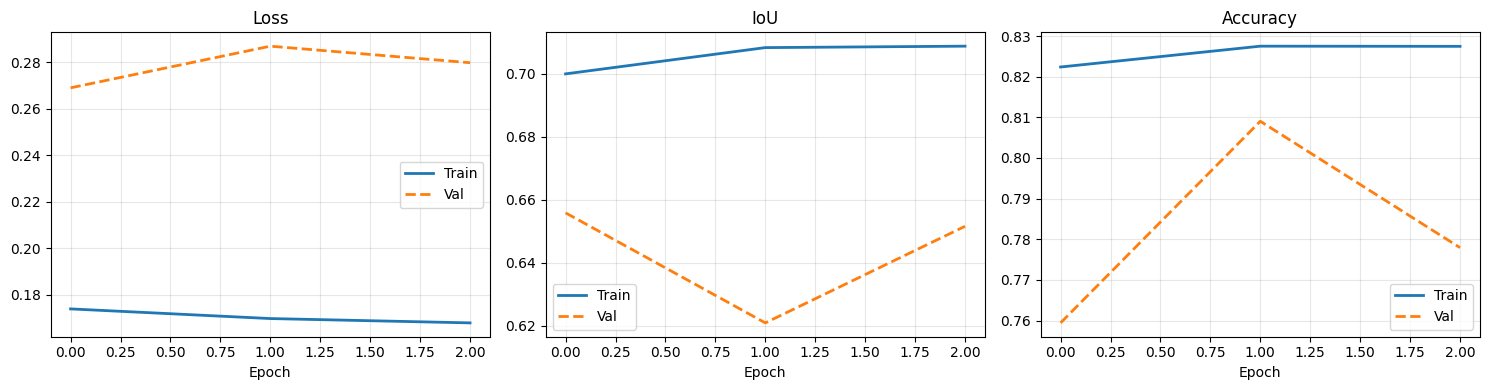

Train | 41/50: 100%|██████████████████████████| 296/296 [06:21<00:00,  1.29s/it, Loss:0.1678 IoU:0.7134 Acc:0.8319]
Valid | 41/50: 100%|███████████████████████████████████████| 99/99 [01:29<00:00,  1.11it/s, Loss:0.2878 IoU:0.6451]



[041/50]  LR: 0.000079
  Train → Loss:0.1678  IoU:0.7134  Acc:0.8319
  Val   → Loss:0.2878  IoU:0.6451  Acc:0.7580


Train | 42/50: 100%|██████████████████████████| 296/296 [06:30<00:00,  1.32s/it, Loss:0.1649 IoU:0.7133 Acc:0.8323]
Valid | 42/50: 100%|███████████████████████████████████████| 99/99 [01:29<00:00,  1.10it/s, Loss:0.2879 IoU:0.6493]



[042/50]  LR: 0.000063
  Train → Loss:0.1649  IoU:0.7133  Acc:0.8323
  Val   → Loss:0.2879  IoU:0.6493  Acc:0.7516


Train | 43/50: 100%|██████████████████████████| 296/296 [06:28<00:00,  1.31s/it, Loss:0.1637 IoU:0.7157 Acc:0.8303]
Valid | 43/50: 100%|███████████████████████████████████████| 99/99 [01:30<00:00,  1.09it/s, Loss:0.2859 IoU:0.6444]


...


[048/50]  LR: 0.000005
  Train → Loss:0.1613  IoU:0.7218  Acc:0.8346
  Val   → Loss:0.2776  IoU:0.6531  Acc:0.7645


Train | 49/50: 100%|██████████████████████████| 296/296 [06:23<00:00,  1.29s/it, Loss:0.1604 IoU:0.7268 Acc:0.8396]
Valid | 49/50: 100%|███████████████████████████████████████| 99/99 [01:29<00:00,  1.11it/s, Loss:0.2753 IoU:0.6516]



[049/50]  LR: 0.000002
  Train → Loss:0.1604  IoU:0.7268  Acc:0.8396
  Val   → Loss:0.2753  IoU:0.6516  Acc:0.7852


Train | 50/50: 100%|██████████████████████████| 296/296 [06:30<00:00,  1.32s/it, Loss:0.1605 IoU:0.7232 Acc:0.8353]
Valid | 50/50: 100%|███████████████████████████████████████| 99/99 [01:30<00:00,  1.10it/s, Loss:0.2758 IoU:0.6459]



[050/50]  LR: 0.000001
  Train → Loss:0.1605  IoU:0.7232  Acc:0.8353
  Val   → Loss:0.2758  IoU:0.6459  Acc:0.7865
  Plot saved: model_checkpoint/3D_UNet_BraTS2024/version_0/training_curves.png


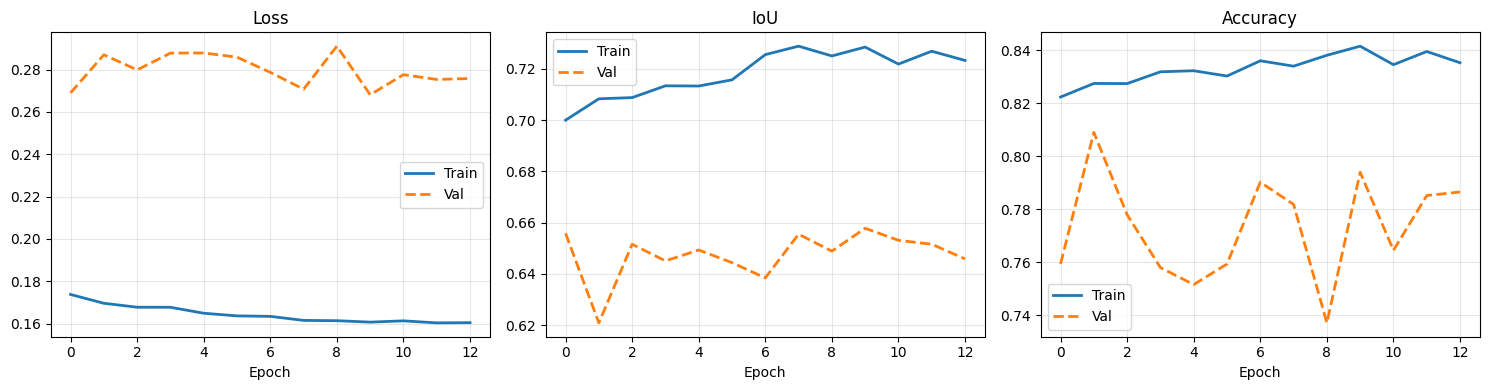


✓ Training complete. Best val loss: 0.2681
  Plot saved: model_checkpoint/3D_UNet_BraTS2024/version_0/training_curves.png


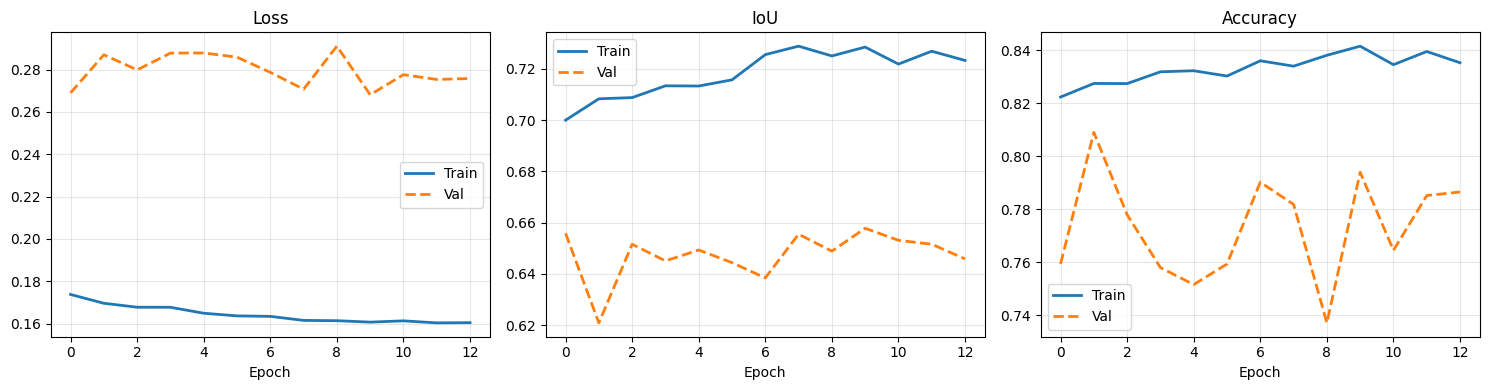

✓ Best model loaded: epoch 47  val_loss=0.2681  val_IoU=0.6578


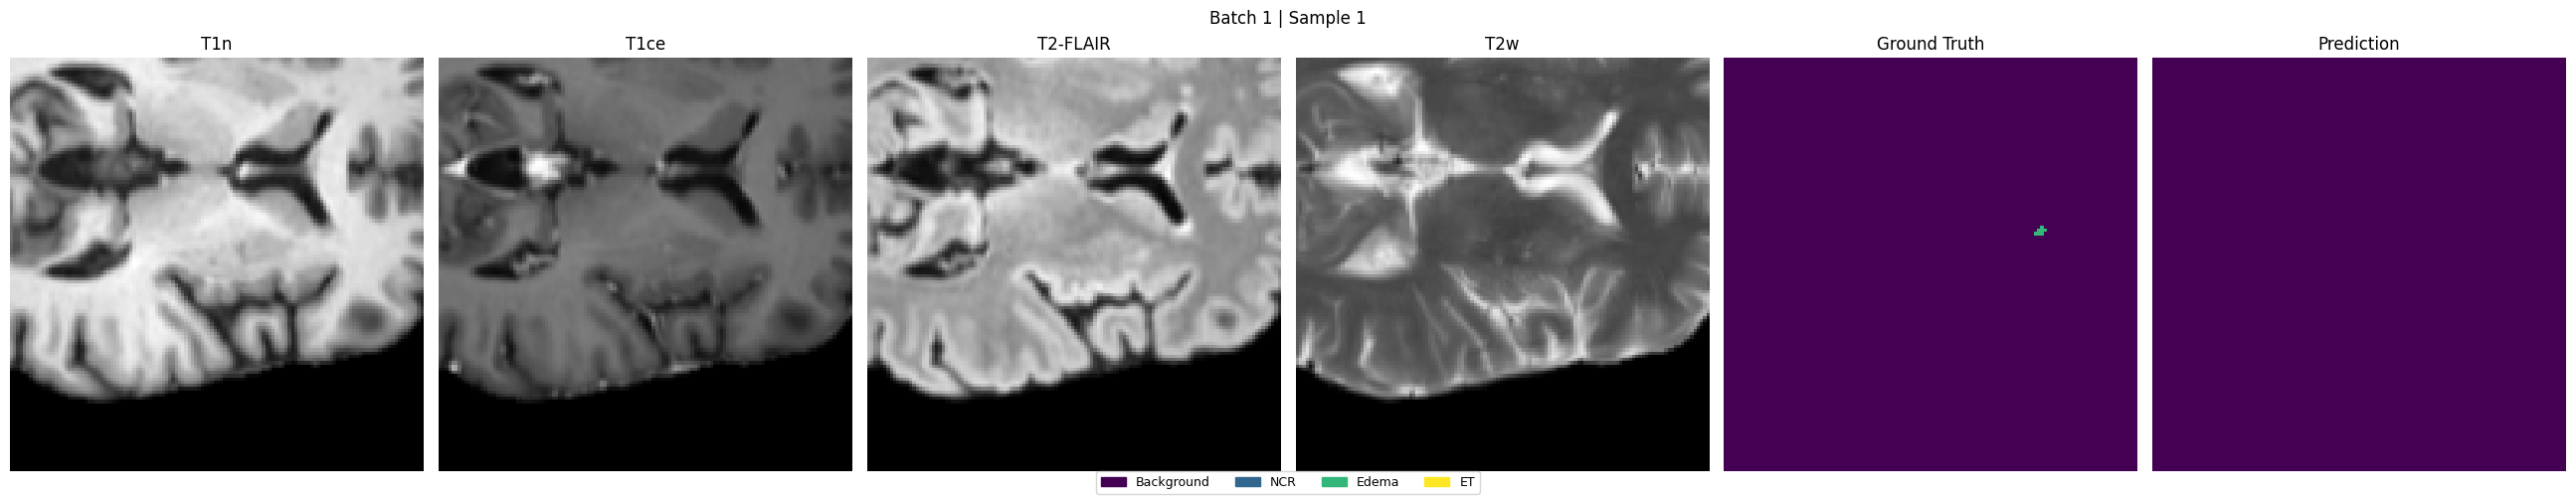

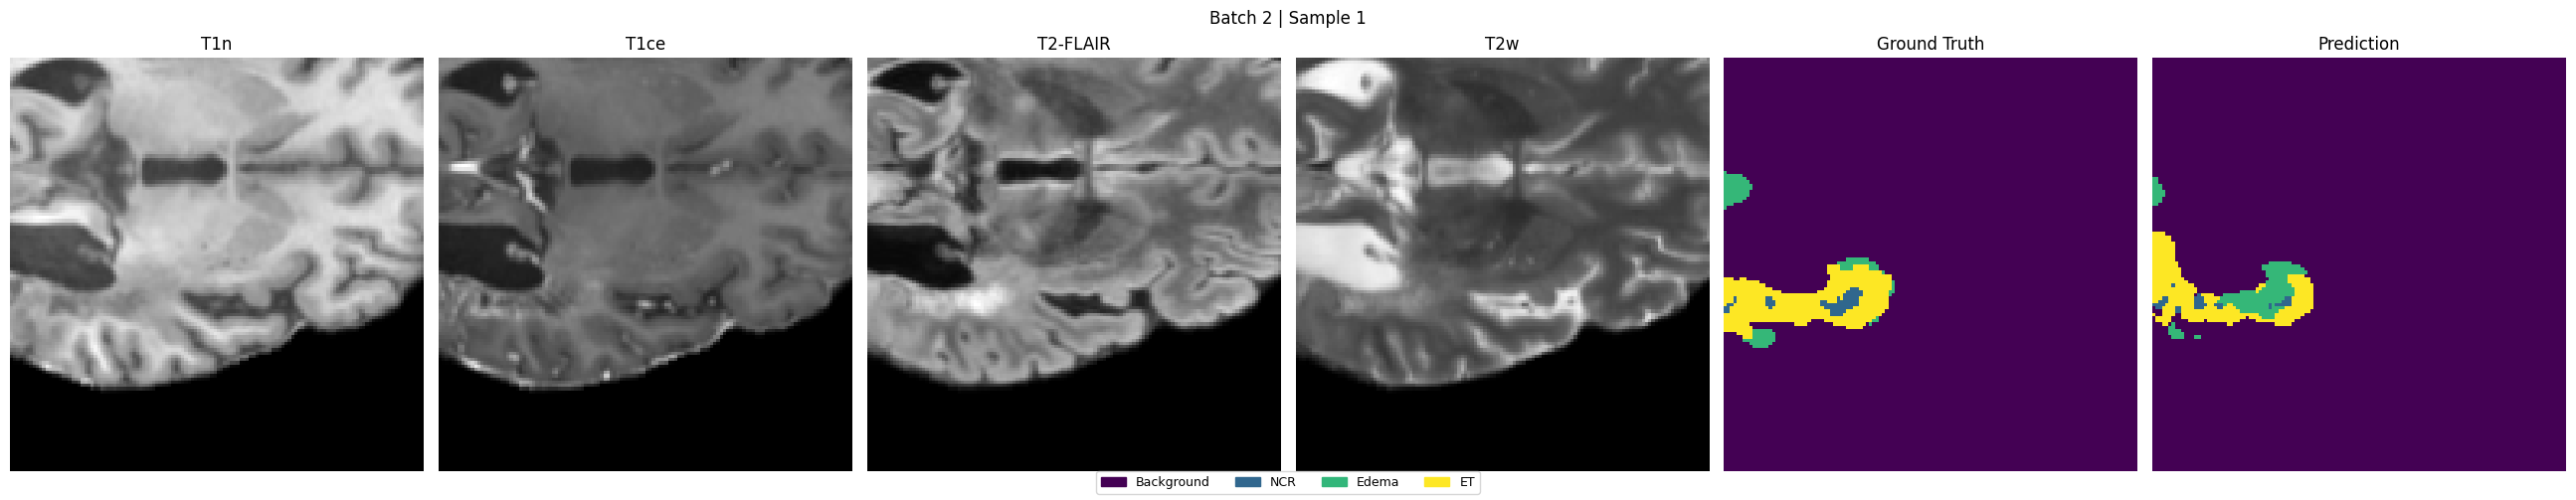

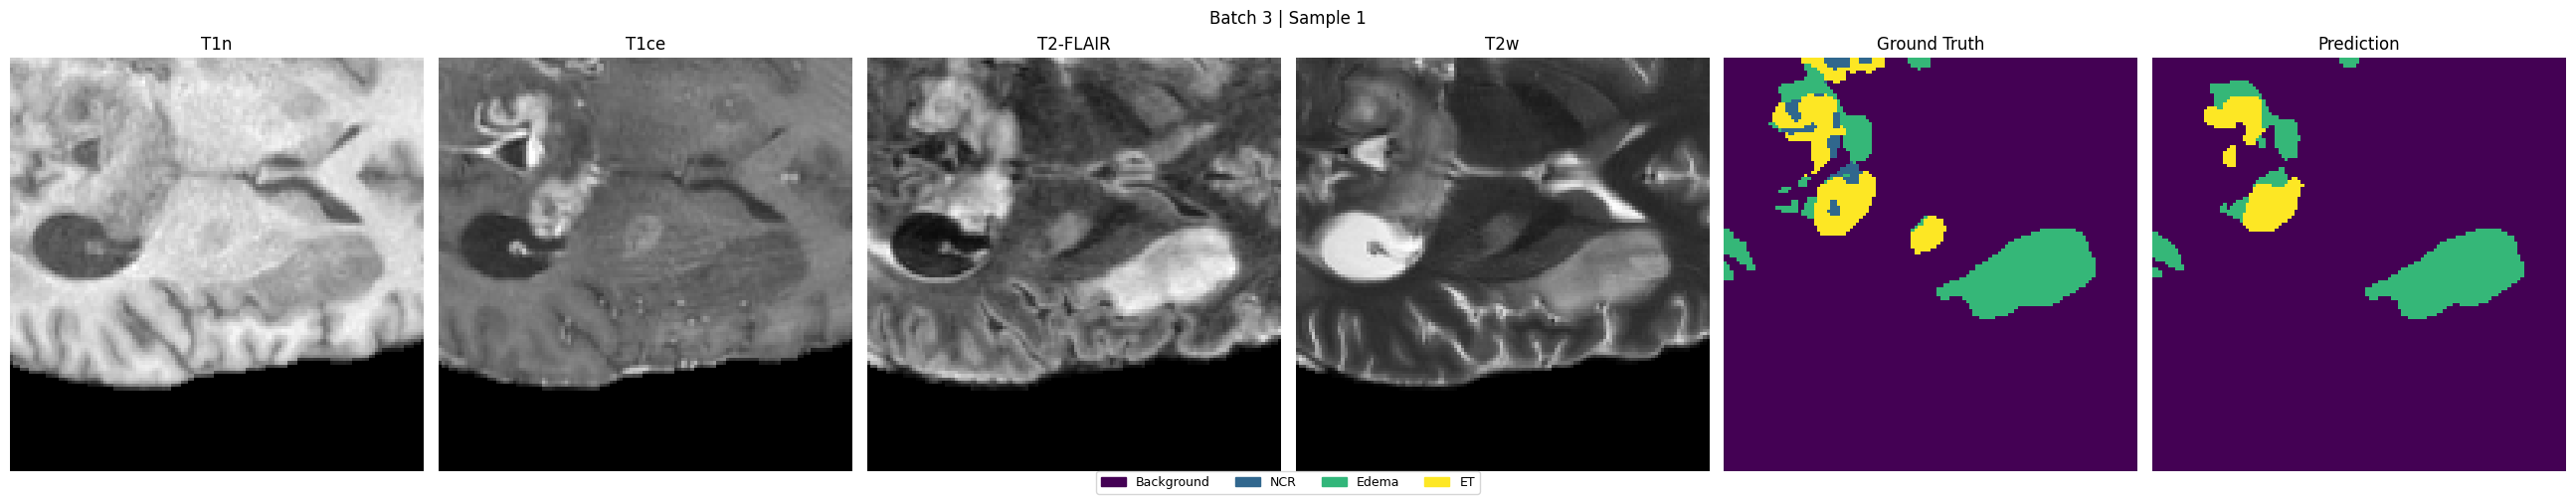

In [ ]:
# ── 1. Collect valid cases and sample ──────────────────────────────────────
valid_cases = collect_cases(CFG.DATASET_PATH)
selected    = sample_files(valid_cases, CFG.NUM_FILES_TO_USE, CFG.RANDOM_SEED)

# ── 2. Wipe stale preprocessed data and rerun fresh ────────────────────────
# This prevents old incomplete .npy files (from earlier failed runs) from
# being silently reused. Preprocessing is skipped on reconnect via Drive.
preproc_base = CFG.PREPROCESSED_PATH
drive_preproc = os.path.join(CFG.DRIVE_BASE, "preprocessed")

# Check if valid preprocessed data exists on Drive first
drive_preproc_img = os.path.join(drive_preproc, "images")
if os.path.exists(drive_preproc_img) and len(os.listdir(drive_preproc_img)) > 10:
    print(f"✓ Found {len(os.listdir(drive_preproc_img))} preprocessed files on Drive, copying locally...")
    if os.path.exists(preproc_base):
        shutil.rmtree(preproc_base)
    shutil.copytree(drive_preproc, preproc_base)
    print("✓ Copied from Drive.")
else:
    # Fresh preprocessing
    if os.path.exists(preproc_base):
        print(f"Wiping old preprocessed data at: {preproc_base}")
        shutil.rmtree(preproc_base)
    preprocess_dataset(CFG.DATASET_PATH, selected, CFG.PREPROCESSED_PATH)
    # Mirror preprocessed data to Drive for future sessions
    print("Mirroring preprocessed data to Drive...")
    if os.path.exists(drive_preproc):
        shutil.rmtree(drive_preproc)
    shutil.copytree(preproc_base, drive_preproc)
    print(f"✓ Mirrored to {drive_preproc}")

# ── 3. Train/val split ──────────────────────────────────────────────────────
tr_img = os.path.join(CFG.PREPROCESSED_PATH, "train", "images")
if not (os.path.exists(tr_img) and len(os.listdir(tr_img)) > 0):
    create_train_val_split(CFG.PREPROCESSED_PATH, CFG.TRAIN_RATIO, CFG.RANDOM_SEED)

# ── 4. Datasets & DataLoaders ───────────────────────────────────────────────
train_ds = BraTS2024Dataset(
    os.path.join(CFG.PREPROCESSED_PATH, "train", "images"),
    os.path.join(CFG.PREPROCESSED_PATH, "train", "masks"),
)
val_ds = BraTS2024Dataset(
    os.path.join(CFG.PREPROCESSED_PATH, "val", "images"),
    os.path.join(CFG.PREPROCESSED_PATH, "val", "masks"),
)
print(f"Train: {len(train_ds)} | Val: {len(val_ds)}")

train_loader = DataLoader(
    train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY,
    prefetch_factor=2,
)
val_loader = DataLoader(
    val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY,
)

# Sanity check
imgs, msks = next(iter(train_loader))
print(f"Image batch: {imgs.shape}")  # expect (1, 4, 128, 128, 128)
print(f"Mask  batch: {msks.shape}")  # expect (1, 4, 128, 128, 128)
assert imgs.shape[1] == 4 and imgs.shape[2:] == (128, 128, 128), \
    f"Unexpected image shape: {imgs.shape}"

# ── 5. Model / Optimizer / Scheduler ────────────────────────────────────────
model = UNet3D_Heterogeneous(
    in_channels=CFG.IN_CHANNELS,
    num_classes=CFG.OUT_CHANNELS,
).to(DEVICE)

optimizer = AdamW(
    model.parameters(),
    lr=CFG.LEARNING_RATE,
    weight_decay=CFG.WEIGHT_DECAY,
    amsgrad=True,
)

scheduler = CosineAnnealingLR(
    optimizer, T_max=CFG.EPOCHS, eta_min=1e-6
)

CKPT_DIR       = create_checkpoint_dir(CFG.CHECKPOINT_DIR)
DRIVE_CKPT_DIR = os.path.join(CFG.DRIVE_BASE, "checkpoints")

# ── 6. Auto-resume from checkpoint ──────────────────────────────────────────
start_epoch = 1
best_loss   = float("inf")

resume_paths = [
    os.path.join(DRIVE_CKPT_DIR, "latest_ckpt.tar"),  # Drive latest (survives disconnects)
    os.path.join(DRIVE_CKPT_DIR, "best_ckpt.tar"),    # Drive best (fallback)
    os.path.join(CKPT_DIR,       "latest_ckpt.tar"),  # local latest
    os.path.join(CKPT_DIR,       "best_ckpt.tar"),    # local best
]

for ckpt_path in resume_paths:
    if os.path.exists(ckpt_path):
        print(f"✓ Checkpoint found: {ckpt_path}")
        start_epoch, best_loss = load_checkpoint(
            model, optimizer, scheduler,
            ckpt_path=ckpt_path, device=DEVICE
        )
        print(f"  ↪ Resuming from epoch {start_epoch} | "
              f"LR: {optimizer.param_groups[0]['lr']:.6f} | "
              f"Best loss: {best_loss:.4f}")
        break
else:
    print("✗ No checkpoint found — starting fresh from epoch 1.")

# ── 7. Train ─────────────────────────────────────────────────────────────────
history = main_train(
    model, optimizer, scheduler,
    train_loader, val_loader,
    ckpt_dir=CKPT_DIR,
    drive_ckpt_dir=DRIVE_CKPT_DIR,
    start_epoch=start_epoch,
    best_loss=best_loss,
    amp_enabled=CFG.AMP_ENABLED,
)

# ── 8. Final training curves ─────────────────────────────────────────────────
plot_history(history, save_path=CKPT_DIR)

# ── 9. Load best model and run inference ─────────────────────────────────────
best_model = UNet3D_Heterogeneous(
    in_channels=CFG.IN_CHANNELS,
    num_classes=CFG.OUT_CHANNELS,
).to(DEVICE)

ckpt = torch.load(os.path.join(CKPT_DIR, "best_ckpt.tar"), map_location=DEVICE)
best_model.load_state_dict(ckpt["model"])
print(f"✓ Best model loaded: epoch {ckpt['epoch']}  "
      f"val_loss={ckpt['val_loss']:.4f}  val_IoU={ckpt['val_iou']:.4f}")

run_inference(best_model, val_loader, DEVICE, num_batches=3)

In [ ]:
# Quick check — run this before Cell 19
test_model = UNet3D_Heterogeneous(in_channels=4, num_classes=4).to(DEVICE)
print("Layer names in your model:")
for name, _ in test_model.named_children():
    print(f"  {name}")
del test_model



Layer names in your model:
  enc1
  pool1
  enc2a
  enc2b
  pool2
  enc3a
  enc3b
  pool3
  bottleneck
  up1
  dec1
  up2
  dec2
  up3
  dec3
  input_skip
  seg_head
  aux_head


In [ ]:
import os, numpy as np, torch
from tqdm import tqdm
import torch.nn.functional as F

FEAT_SAVE_PATH = "/content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round1.pt"
val_img_dir    = "/content/drive/MyDrive/BraTS2024_3DUNet/preprocessed/images"
NUM_VOLUMES    = 20

vol_files    = sorted(os.listdir(val_img_dir))[:NUM_VOLUMES]
all_features = []

print(f"Extracting features from {len(vol_files)} volumes...")

feat_model.eval()
with torch.no_grad():
    for vol_idx, fname in enumerate(tqdm(vol_files, desc="Extracting")):

        vol = np.load(os.path.join(val_img_dir, fname))        # (H,W,D,C)
        vol = torch.from_numpy(vol).permute(3, 2, 0, 1).float() # (C,D,H,W)

        if vol.shape[1:] != (128, 128, 128):
            vol = F.interpolate(vol.unsqueeze(0), size=(128,128,128),
                                mode='trilinear', align_corners=False).squeeze(0)

        mean = vol.mean(dim=(1,2,3), keepdim=True)
        std  = vol.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
        vol  = (vol - mean) / std

        vol = vol.unsqueeze(0).to(DEVICE)   # (1, 4, 128, 128, 128)

        # Encoder forward pass — stop at bottleneck
        e1         = feat_model.enc1(vol)
        p1         = feat_model.pool1(e1)
        e2a        = feat_model.enc2a(p1)
        e2b        = feat_model.enc2b(e2a)
        p2         = feat_model.pool2(e2b)
        e3a        = feat_model.enc3a(p2)
        e3b        = feat_model.enc3b(e3a)
        p3         = feat_model.pool3(e3b)
        bottleneck = feat_model.bottleneck(p3)   # (1, 256, 16, 16, 16)

        all_features.append(bottleneck.cpu())
        print(f"  [{vol_idx+1:02d}/{NUM_VOLUMES}] {fname} — shape: {bottleneck.shape}")

        del vol, e1, p1, e2a, e2b, p2, e3a, e3b, p3, bottleneck
        torch.cuda.empty_cache()

# ── Save ──────────────────────────────────────────────────────────────────────
feat_3d = torch.cat(all_features, dim=0)   # (20, 256, 16, 16, 16)
os.makedirs(os.path.dirname(FEAT_SAVE_PATH), exist_ok=True)
torch.save(feat_3d, FEAT_SAVE_PATH)

print(f"\n✓ feat_3d_round1.pt saved")
print(f"  Shape : {feat_3d.shape}")
print(f"  Size  : {feat_3d.element_size() * feat_3d.nelement() / 1e6:.1f} MB")
print(f"  Path  : {FEAT_SAVE_PATH}")

In [ ]:
feat_3d = torch.cat(all_features, dim=0)
torch.save(feat_3d, FEAT_SAVE_PATH)
print(f"✓ Saved — Shape: {feat_3d.shape}")
print(f"  Size : {feat_3d.element_size() * feat_3d.nelement() / 1e6:.1f} MB")
print(f"  Path : {FEAT_SAVE_PATH}")

✓ Saved — Shape: torch.Size([20, 256, 16, 16, 16])
  Size : 83.9 MB
  Path : /content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round1.pt


In [ ]:
import gdown, os, torch
import torch.nn.functional as F
import numpy as np
from tqdm import tqdm

DRIVE_BASE     = '/content/drive/MyDrive/BraTS2024_3DUNet'
DRIVE_CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')
GUIDANCE_PATH  = os.path.join(DRIVE_BASE, 'guidance_round1.pt')
ROUND2_CKPT    = os.path.join(DRIVE_CKPT_DIR, 'round2_ckpt.tar')

# Download guidance from server
if not os.path.exists(GUIDANCE_PATH):
    FILE_ID = "10BVbalrPuLuuoTfpXj9SSX00ibh7RQKK"
    gdown.download(
        f"https://drive.google.com/uc?id={FILE_ID}",
        GUIDANCE_PATH, quiet=False
    )

guidance = torch.load(GUIDANCE_PATH, map_location='cpu')
print(f"✓ guidance_round1.pt loaded")
print(f"  Shape : {guidance.shape}")
print(f"  Mean  : {guidance.mean():.4f}")
print(f"  Max   : {guidance.max():.4f}")

✓ guidance_round1.pt loaded
  Shape : torch.Size([20, 256, 16, 16, 16])
  Mean  : 0.1783
  Max   : 14.7007


In [ ]:
import torch.nn as nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

# Load best checkpoint from Round 1
model = UNet3D_Heterogeneous(in_channels=4, num_classes=4).to(DEVICE)
ckpt  = torch.load(os.path.join(DRIVE_CKPT_DIR, 'best_ckpt.tar'), map_location=DEVICE)
model.load_state_dict(ckpt['model'])
print(f"✓ Loaded Round 1 best checkpoint")
print(f"  Epoch   : {ckpt['epoch']}")
print(f"  Val IoU : {ckpt['val_iou']:.4f}")

# Guidance injection layer — compresses concat(bottleneck, guidance) back to 256ch
guidance_inject = nn.Conv3d(512, 256, kernel_size=1, bias=False).to(DEVICE)
nn.init.kaiming_normal_(guidance_inject.weight, mode='fan_out', nonlinearity='relu')

# Compute mean guidance across 20 volumes — used for injection
# Shape: (1, 256, 16, 16, 16)
guidance_mean = guidance.mean(dim=0, keepdim=True).to(DEVICE)
print(f"✓ Guidance injection layer ready")
print(f"  guidance_mean shape: {guidance_mean.shape}")

✓ Loaded Round 1 best checkpoint
  Epoch   : 47
  Val IoU : 0.6578
✓ Guidance injection layer ready
  guidance_mean shape: torch.Size([1, 256, 16, 16, 16])


In [ ]:

from segmentation_models_pytorch import losses as smp_losses
from torchmetrics import MeanMetric
from torchmetrics.classification import MulticlassAccuracy
import torch.nn.functional as F

FINETUNE_EPOCHS = 10
GUIDANCE_LR     = 5e-5   # conservative — preserve Round 1 learning

# Rebuild DataLoaders
preproc_base = CFG.PREPROCESSED_PATH
drive_preproc = os.path.join(DRIVE_BASE, 'preprocessed')

if not os.path.exists(os.path.join(preproc_base, 'train', 'images')):
    import shutil
    if os.path.exists(preproc_base):
        shutil.rmtree(preproc_base)
    shutil.copytree(drive_preproc, preproc_base)
    create_train_val_split(preproc_base, CFG.TRAIN_RATIO, CFG.RANDOM_SEED)

train_ds = BraTS2024Dataset(
    os.path.join(preproc_base, 'train', 'images'),
    os.path.join(preproc_base, 'train', 'masks'),
)
val_ds = BraTS2024Dataset(
    os.path.join(preproc_base, 'val', 'images'),
    os.path.join(preproc_base, 'val', 'masks'),
)
train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY, prefetch_factor=2)
val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY)
print(f"✓ DataLoaders ready — Train: {len(train_ds)} | Val: {len(val_ds)}")

# Optimizer
optimizer = AdamW([
    {'params': model.parameters(),            'lr': GUIDANCE_LR},
    {'params': guidance_inject.parameters(),  'lr': GUIDANCE_LR * 2},
], weight_decay=CFG.WEIGHT_DECAY, amsgrad=True)

scheduler  = CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6)
scaler     = torch.amp.GradScaler('cuda', enabled=CFG.AMP_ENABLED)
best_loss  = float('inf')

_dice_loss  = smp_losses.DiceLoss(mode='multiclass', from_logits=True, smooth=1e-5, eps=1e-7)
_focal_loss = smp_losses.FocalLoss(mode='multiclass', alpha=0.25, gamma=2.0)
_bce_loss   = nn.BCEWithLogitsLoss()

def combined_loss_r2(seg_out, aux_out, target_cls, target_binary):
    return (_dice_loss(seg_out, target_cls) +
            _focal_loss(seg_out, target_cls) +
            0.3 * _bce_loss(aux_out, target_binary.float()))

print(f"\nStarting Round 2 guided fine-tuning — {FINETUNE_EPOCHS} epochs")
print("=" * 60)

for epoch in range(1, FINETUNE_EPOCHS + 1):
    # ── Train ────────────────────────────────────────────────────────────────
    model.train()
    guidance_inject.train()
    loss_sum, steps = 0.0, 0
    optimizer.zero_grad()

    for step, (images, masks) in enumerate(tqdm(train_loader, desc=f"R2 Train {epoch}/{FINETUNE_EPOCHS}", ncols=100)):
        images = images.to(DEVICE, non_blocking=True).float()
        masks  = masks.to(DEVICE,  non_blocking=True).float()

        target_cls    = masks.argmax(dim=1)
        target_binary = (target_cls > 0).unsqueeze(1).float()

        with torch.amp.autocast('cuda', enabled=CFG.AMP_ENABLED):
            # Encoder forward
            e1 = model.enc1(images)
            p1 = model.pool1(e1)
            e2a = model.enc2a(p1); e2b = model.enc2b(e2a)
            p2 = model.pool2(e2b)
            e3a = model.enc3a(p2); e3b = model.enc3b(e3a)
            p3 = model.pool3(e3b)
            bottleneck = model.bottleneck(p3)

            # Inject guidance
            g = guidance_mean.expand(images.shape[0], -1, -1, -1, -1)
            enriched = guidance_inject(torch.cat([bottleneck, g], dim=1))

            # Manual Decoder Step-by-Step
            d1 = model.up1(enriched)
            if d1.shape[2:] != e3b.shape[2:]:
                d1 = F.interpolate(d1, size=e3b.shape[2:], mode='trilinear', align_corners=False)
            d1 = torch.cat([d1, e3b], dim=1)
            d1 = model.dec1(d1)

            d2 = model.up2(d1)
            if d2.shape[2:] != e2b.shape[2:]:
                d2 = F.interpolate(d2, size=e2b.shape[2:], mode='trilinear', align_corners=False)
            d2 = torch.cat([d2, e2b], dim=1)
            d2 = model.dec2(d2)

            d3 = model.up3(d2)
            if d3.shape[2:] != e1.shape[2:]:
                d3 = F.interpolate(d3, size=e1.shape[2:], mode='trilinear', align_corners=False)
            d3 = torch.cat([d3, e1], dim=1)
            d3 = model.dec3(d3)

            skip_in = model.input_skip(images)
            if skip_in.shape[2:] != d3.shape[2:]:
                skip_in = F.interpolate(skip_in, size=d3.shape[2:], mode='trilinear', align_corners=False)

            d_out = torch.cat([d3, skip_in], dim=1)
            seg_out = model.seg_head(d_out)
            aux_out = model.aux_head(d_out)

            loss = combined_loss_r2(seg_out, aux_out, target_cls, target_binary)
            loss = loss / CFG.GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()

        if (step + 1) % CFG.GRAD_ACCUM_STEPS == 0 or (step+1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(list(model.parameters()) + list(guidance_inject.parameters()), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        loss_sum += loss.item() * CFG.GRAD_ACCUM_STEPS
        steps    += 1
        del images, masks, seg_out, aux_out

    scheduler.step()
    avg_train = loss_sum / steps

    # ── Validate ─────────────────────────────────────────────────────────────
    model.eval()
    guidance_inject.eval()
    val_loss_sum, val_iou_sum, val_steps = 0.0, 0.0, 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE).float()
            masks  = masks.to(DEVICE).float()
            target_cls    = masks.argmax(dim=1)
            target_binary = (target_cls > 0).unsqueeze(1).float()

            with torch.amp.autocast('cuda', enabled=CFG.AMP_ENABLED):
                e1 = model.enc1(images)
                p1 = model.pool1(e1)
                e2a = model.enc2a(p1); e2b = model.enc2b(e2a)
                p2 = model.pool2(e2b)
                e3a = model.enc3a(p2); e3b = model.enc3b(e3a)
                p3 = model.pool3(e3b)
                bottleneck = model.bottleneck(p3)
                g = guidance_mean.expand(images.shape[0], -1, -1, -1, -1)
                enriched = guidance_inject(torch.cat([bottleneck, g], dim=1))

                # Manual Decoder Step-by-Step
                d1 = model.up1(enriched)
                if d1.shape[2:] != e3b.shape[2:]:
                    d1 = F.interpolate(d1, size=e3b.shape[2:], mode='trilinear', align_corners=False)
                d1 = torch.cat([d1, e3b], dim=1)
                d1 = model.dec1(d1)

                d2 = model.up2(d1)
                if d2.shape[2:] != e2b.shape[2:]:
                    d2 = F.interpolate(d2, size=e2b.shape[2:], mode='trilinear', align_corners=False)
                d2 = torch.cat([d2, e2b], dim=1)
                d2 = model.dec2(d2)

                d3 = model.up3(d2)
                if d3.shape[2:] != e1.shape[2:]:
                    d3 = F.interpolate(d3, size=e1.shape[2:], mode='trilinear', align_corners=False)
                d3 = torch.cat([d3, e1], dim=1)
                d3 = model.dec3(d3)

                skip_in = model.input_skip(images)
                if skip_in.shape[2:] != d3.shape[2:]:
                    skip_in = F.interpolate(skip_in, size=d3.shape[2:], mode='trilinear', align_corners=False)

                d_out = torch.cat([d3, skip_in], dim=1)
                seg_out = model.seg_head(d_out)
                aux_out = model.aux_head(d_out)

                loss = combined_loss_r2(seg_out, aux_out, target_cls, target_binary)

            import segmentation_models_pytorch as smp
            pred = seg_out.argmax(dim=1)
            tp, fp, fn, tn = smp.metrics.get_stats(pred, target_cls, mode='multiclass', num_classes=4)
            iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction='macro')

            val_loss_sum += loss.item()
            val_iou_sum  += iou.item()
            val_steps    += 1
            del images, masks, seg_out, aux_out

    avg_val_loss = val_loss_sum / val_steps
    avg_val_iou  = val_iou_sum  / val_steps
    lr_now = optimizer.param_groups[0]['lr']

    print(f"\n[R2 {epoch:02d}/{FINETUNE_EPOCHS}]  LR: {lr_now:.6f}")
    print(f"  Train Loss : {avg_train:.4f}")
    print(f"  Val Loss   : {avg_val_loss:.4f}  Val IoU: {avg_val_iou:.4f}")

    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        torch.save({
            'epoch'           : epoch,
            'model'           : model.state_dict(),
            'guidance_inject' : guidance_inject.state_dict(),
            'optimizer'       : optimizer.state_dict(),
            'scheduler'       : scheduler.state_dict(),
            'val_loss'        : avg_val_loss,
            'val_iou'         : avg_val_iou,
        }, ROUND2_CKPT)
        print(f"  ★ round2_ckpt.tar saved (val_loss={avg_val_loss:.4f})")

print(f"\n✓ Round 2 complete. Best val loss: {best_loss:.4f}")
print(f"  Saved: {ROUND2_CKPT}")

✓ Split — Train: 296 | Val: 99
✓ DataLoaders ready — Train: 296 | Val: 99

Starting Round 2 guided fine-tuning — 10 epochs


R2 Train 1/10: 100%|██████████████████████████████████████████████| 296/296 [06:01<00:00,  1.22s/it]



[R2 01/10]  LR: 0.000049
  Train Loss : 0.2039
  Val Loss   : 0.2727  Val IoU: 0.6476
  ★ round2_ckpt.tar saved (val_loss=0.2727)


R2 Train 2/10: 100%|██████████████████████████████████████████████| 296/296 [06:01<00:00,  1.22s/it]



[R2 02/10]  LR: 0.000045
  Train Loss : 0.1740
  Val Loss   : 0.2675  Val IoU: 0.6512
  ★ round2_ckpt.tar saved (val_loss=0.2675)


...


[R2 08/10]  LR: 0.000006
  Train Loss : 0.1616
  Val Loss   : 0.2754  Val IoU: 0.6260


R2 Train 9/10: 100%|██████████████████████████████████████████████| 296/296 [05:59<00:00,  1.22s/it]



[R2 09/10]  LR: 0.000002
  Train Loss : 0.1619
  Val Loss   : 0.2667  Val IoU: 0.6448
  ★ round2_ckpt.tar saved (val_loss=0.2667)


R2 Train 10/10: 100%|█████████████████████████████████████████████| 296/296 [05:58<00:00,  1.21s/it]



[R2 10/10]  LR: 0.000001
  Train Loss : 0.1629
  Val Loss   : 0.2739  Val IoU: 0.6554

✓ Round 2 complete. Best val loss: 0.2667
  Saved: /content/drive/MyDrive/BraTS2024_3DUNet/checkpoints/round2_ckpt.tar


In [ ]:
FEAT_SAVE_PATH = os.path.join(DRIVE_BASE, 'features', 'feat_3d_round2.pt')
val_img_dir    = os.path.join(DRIVE_BASE, 'preprocessed', 'images')
NUM_VOLUMES    = 20

# Load round2 checkpoint
ckpt = torch.load(ROUND2_CKPT, map_location=DEVICE)
model.load_state_dict(ckpt['model'])
guidance_inject.load_state_dict(ckpt['guidance_inject'])
model.eval()
guidance_inject.eval()
print(f"✓ Round 2 checkpoint loaded — epoch {ckpt['epoch']} IoU {ckpt['val_iou']:.4f}")

vol_files    = sorted(os.listdir(val_img_dir))[:NUM_VOLUMES]
all_features = []

with torch.no_grad():
    for vol_idx, fname in enumerate(tqdm(vol_files, desc="Extracting R2 features")):
        vol = np.load(os.path.join(val_img_dir, fname))
        vol = torch.from_numpy(vol).permute(3, 2, 0, 1).float()
        if vol.shape[1:] != (128, 128, 128):
            vol = F.interpolate(vol.unsqueeze(0), size=(128,128,128),
                                mode='trilinear', align_corners=False).squeeze(0)
        mean = vol.mean(dim=(1,2,3), keepdim=True)
        std  = vol.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
        vol  = ((vol - mean) / std).unsqueeze(0).to(DEVICE)

        e1  = model.enc1(vol)
        p1  = model.pool1(e1)
        e2a = model.enc2a(p1);  e2b = model.enc2b(e2a)
        p2  = model.pool2(e2b)
        e3a = model.enc3a(p2);  e3b = model.enc3b(e3a)
        p3  = model.pool3(e3b)
        bottleneck = model.bottleneck(p3)
        g   = guidance_mean.expand(1, -1, -1, -1, -1)
        enriched = guidance_inject(torch.cat([bottleneck, g], dim=1))

        all_features.append(enriched.cpu())
        print(f"  [{vol_idx+1:02d}/{NUM_VOLUMES}] {fname} — {enriched.shape}")
        del vol, enriched
        torch.cuda.empty_cache()

feat_3d_r2 = torch.cat(all_features, dim=0)
torch.save(feat_3d_r2, FEAT_SAVE_PATH)
print(f"\n✓ feat_3d_round2.pt saved")
print(f"  Shape : {feat_3d_r2.shape}")
print(f"  Path  : {FEAT_SAVE_PATH}")

✓ Round 2 checkpoint loaded — epoch 9 IoU 0.6448


Extracting R2 features:   5%|▌         | 1/20 [00:03<01:00,  3.18s/it]

  [01/20] image_0000.npy — torch.Size([1, 256, 16, 16, 16])


Extracting R2 features:  10%|█         | 2/20 [00:05<00:46,  2.56s/it]

  [02/20] image_0001.npy — torch.Size([1, 256, 16, 16, 16])


...

Extracting R2 features:  95%|█████████▌| 19/20 [00:38<00:01,  1.71s/it]

  [19/20] image_0022.npy — torch.Size([1, 256, 16, 16, 16])


Extracting R2 features: 100%|██████████| 20/20 [00:40<00:00,  2.03s/it]

  [20/20] image_0023.npy — torch.Size([1, 256, 16, 16, 16])



✓ feat_3d_round2.pt saved
  Shape : torch.Size([20, 256, 16, 16, 16])
  Path  : /content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round2.pt


In [ ]:
import os, numpy as np, torch
from tqdm import tqdm
import torch.nn.functional as F
import torch.nn as nn

DRIVE_BASE     = '/content/drive/MyDrive/BraTS2024_3DUNet'
DRIVE_CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')
FEAT_SAVE_PATH = os.path.join(DRIVE_BASE, 'features', 'feat_3d_round2.pt')
ROUND2_CKPT    = os.path.join(DRIVE_CKPT_DIR, 'round2_ckpt.tar')
GUIDANCE_PATH  = os.path.join(DRIVE_BASE, 'guidance_round1.pt')
NUM_VOLUMES    = 20

os.makedirs(os.path.dirname(FEAT_SAVE_PATH), exist_ok=True)

# ── Rebuild model + injection layer ──────────────────────────────────────────
feat_model      = UNet3D_Heterogeneous(in_channels=4, num_classes=4).to(DEVICE)
guidance_inject = nn.Conv3d(512, 256, kernel_size=1, bias=False).to(DEVICE)

ckpt = torch.load(ROUND2_CKPT, map_location=DEVICE)
feat_model.load_state_dict(ckpt['model'])
guidance_inject.load_state_dict(ckpt['guidance_inject'])
feat_model.eval()
guidance_inject.eval()
print(f"✓ round2_ckpt.tar loaded")
print(f"  Epoch   : {ckpt['epoch']}")
print(f"  Val IoU : {ckpt['val_iou']:.4f}")
print(f"  Val Loss: {ckpt['val_loss']:.4f}")

# ── Load guidance mean ────────────────────────────────────────────────────────
guidance      = torch.load(GUIDANCE_PATH, map_location='cpu')
guidance_mean = guidance.mean(dim=0, keepdim=True).to(DEVICE)
print(f"✓ guidance_round1.pt loaded — shape {guidance.shape}")

# ── Val images ────────────────────────────────────────────────────────────────
val_img_dir = os.path.join(DRIVE_BASE, 'preprocessed', 'images')
vol_files   = sorted(os.listdir(val_img_dir))[:NUM_VOLUMES]
print(f"✓ {len(vol_files)} volumes ready for extraction")

# ── Extract enriched bottleneck (bottleneck + guidance injected) ──────────────
all_features = []

with torch.no_grad():
    for vol_idx, fname in enumerate(tqdm(vol_files, desc="Extracting R2 features")):
        vol = np.load(os.path.join(val_img_dir, fname))
        vol = torch.from_numpy(vol).permute(3, 2, 0, 1).float()

        if vol.shape[1:] != (128, 128, 128):
            vol = F.interpolate(vol.unsqueeze(0), size=(128,128,128),
                                mode='trilinear', align_corners=False).squeeze(0)

        mean = vol.mean(dim=(1,2,3), keepdim=True)
        std  = vol.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
        vol  = ((vol - mean) / std).unsqueeze(0).to(DEVICE)

        # Forward through encoder
        e1  = feat_model.enc1(vol)
        p1  = feat_model.pool1(e1)
        e2a = feat_model.enc2a(p1);  e2b = feat_model.enc2b(e2a)
        p2  = feat_model.pool2(e2b)
        e3a = feat_model.enc3a(p2);  e3b = feat_model.enc3b(e3a)
        p3  = feat_model.pool3(e3b)
        bottleneck = feat_model.bottleneck(p3)   # (1, 256, 16, 16, 16)

        # Apply guidance injection — extract enriched features
        g        = guidance_mean.expand(1, -1, -1, -1, -1)
        enriched = guidance_inject(torch.cat([bottleneck, g], dim=1))  # (1, 256, 16, 16, 16)

        all_features.append(enriched.cpu())
        print(f"  [{vol_idx+1:02d}/{NUM_VOLUMES}] {fname} — {enriched.shape}")

        del vol, e1, p1, e2a, e2b, p2, e3a, e3b, p3, bottleneck, enriched
        torch.cuda.empty_cache()

# ── Save ──────────────────────────────────────────────────────────────────────
feat_3d_r2 = torch.cat(all_features, dim=0)   # (20, 256, 16, 16, 16)
torch.save(feat_3d_r2, FEAT_SAVE_PATH)

print(f"\n✓ feat_3d_round2.pt saved")
print(f"  Shape : {feat_3d_r2.shape}")
print(f"  Size  : {feat_3d_r2.element_size() * feat_3d_r2.nelement() / 1e6:.1f} MB")
print(f"  Path  : {FEAT_SAVE_PATH}")

✓ round2_ckpt.tar loaded
  Epoch   : 9
  Val IoU : 0.6448
  Val Loss: 0.2667
✓ guidance_round1.pt loaded — shape torch.Size([20, 256, 16, 16, 16])
✓ 20 volumes ready for extraction


Extracting R2 features:   5%|▌         | 1/20 [00:01<00:22,  1.17s/it]

  [01/20] image_0000.npy — torch.Size([1, 256, 16, 16, 16])


Extracting R2 features:  10%|█         | 2/20 [00:02<00:18,  1.01s/it]

  [02/20] image_0001.npy — torch.Size([1, 256, 16, 16, 16])


...

Extracting R2 features:  95%|█████████▌| 19/20 [00:48<00:02,  2.96s/it]

  [19/20] image_0022.npy — torch.Size([1, 256, 16, 16, 16])


Extracting R2 features: 100%|██████████| 20/20 [00:51<00:00,  2.59s/it]

  [20/20] image_0023.npy — torch.Size([1, 256, 16, 16, 16])



✓ feat_3d_round2.pt saved
  Shape : torch.Size([20, 256, 16, 16, 16])
  Size  : 83.9 MB
  Path  : /content/drive/MyDrive/BraTS2024_3DUNet/features/feat_3d_round2.pt


In [ ]:
!pip install surface-distance -q
print("✓ surface-distance installed")

✓ surface-distance installed


## Round 1 — Inference Visualization (Before & After Guidance Injection)

In [ ]:
import os, gc, shutil, glob
import numpy as np
import nibabel as nib
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
import surface_distance as sd

# ─────────────────────────────────────────────────────────────
# CONFIG
# ─────────────────────────────────────────────────────────────
DRIVE_BASE       = '/content/drive/MyDrive/BraTS2024_3DUNet'
DATASET_PATH     = '/content/drive/MyDrive/test_brats_dataset'
DRIVE_CKPT_DIR   = os.path.join(DRIVE_BASE, 'checkpoints')
GUIDANCE_PATH    = os.path.join(DRIVE_BASE, 'guidance_round1.pt')
RESULTS_DIR      = os.path.join(DRIVE_BASE, 'evaluation_results')
TEST_PREPROC_DIR = '/content/test_preprocessed'

BEST_CKPT   = os.path.join(DRIVE_CKPT_DIR, 'best_ckpt.tar')     # before guidance
ROUND2_CKPT = os.path.join(DRIVE_CKPT_DIR, 'round2_ckpt.tar')   # after guidance

NUM_TEST_PATIENTS = 40
CROP_X = (56, 184)
CROP_Y = (56, 184)
CROP_Z = (13, 141)

CLASS_NAMES  = ["Background", "NCR", "Edema", "ET"]
CLASS_COLORS = ["#6a0dad", "#1f77b4", "#2ca02c", "#FFD700"]
cmap         = plt.cm.colors.ListedColormap(CLASS_COLORS)

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(TEST_PREPROC_DIR, exist_ok=True)

print(f"\u2713 Config ready")
print(f"  Dataset      : {DATASET_PATH}")
print(f"  Results dir  : {RESULTS_DIR}")

✓ Config ready
  Dataset      : /content/drive/MyDrive/test_brats_dataset
  Results dir  : /content/drive/MyDrive/BraTS2024_3DUNet/evaluation_results


In [ ]:
# ─────────────────────────────────────────────────────────────
# STEP 1 — COLLECT 40 HELD-OUT TEST PATIENTS
# ─────────────────────────────────────────────────────────────
import random

def collect_all_cases(root):
    valid = []
    for pid in sorted(os.listdir(root)):
        p = os.path.join(root, pid)
        if not os.path.isdir(p):
            continue
        files = os.listdir(p)
        req   = ["t1c", "t1n", "t2f", "t2w", "seg"]
        if all(any(k in f.lower() and (f.endswith(".nii") or f.endswith(".nii.gz")) for f in files) for k in req):
            valid.append(pid)
    return valid

all_cases = collect_all_cases(DATASET_PATH)
print(f"✓ Total valid cases in dataset: {len(all_cases)}")

# --- Simplified Test Patient Selection ---
# The dataset provided for testing is small (40 cases).
# We will directly sample NUM_TEST_PATIENTS from these available cases.
random.seed(99) # Seed for reproducibility of test patient selection
num_to_select = min(NUM_TEST_PATIENTS, len(all_cases))
test_cases = random.sample(all_cases, num_to_select)

if not test_cases: # Check if the list is empty
    print(f"⚠ No test patients could be selected from {len(all_cases)} available valid cases.")
else:
    print(f"✓ Test patients selected: {len(test_cases)}")
    print(f"  First: {test_cases[0]}")
    print(f"  Last : {test_cases[-1]}")

✓ Total valid cases in dataset: 40
✓ Test patients selected: 40
  First: BraTS-GLI-02194-104
  Last : BraTS-GLI-02609-104


In [ ]:
def load_modality(folder_path, keyword):
    files = [f for f in os.listdir(folder_path)
             if keyword in f.lower() and (f.endswith('.nii.gz') or f.endswith('.nii'))]
    if not files:
        raise FileNotFoundError(f"No file with '{keyword}' in {folder_path}")
    return nib.load(os.path.join(folder_path, files[0])).get_fdata(dtype=np.float32)

def minmax_normalize(vol):
    brain = vol > 0
    if brain.sum() == 0:
        return vol
    vmin, vmax = vol[brain].min(), vol[brain].max()
    if vmax == vmin:
        return np.zeros_like(vol)
    out = np.zeros_like(vol)
    out[brain] = (vol[brain] - vmin) / (vmax - vmin)
    return out

def preprocess_patient(folder_path, cx, cy, cz):
    t1n  = minmax_normalize(load_modality(folder_path, 't1n'))
    t1c  = minmax_normalize(load_modality(folder_path, 't1c'))
    t2f  = minmax_normalize(load_modality(folder_path, 't2f'))
    t2w  = minmax_normalize(load_modality(folder_path, 't2w'))
    seg  = load_modality(folder_path, 'seg').astype(np.int32)
    seg[seg == 4] = 3   # remap label 4→3

    # Crop
    t1n  = t1n[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    t1c  = t1c[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    t2f  = t2f[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    t2w  = t2w[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]
    seg  = seg[cx[0]:cx[1], cy[0]:cy[1], cz[0]:cz[1]]

    image = np.stack([t1n, t1c, t2f, t2w], axis=-1).astype(np.float32)  # (H,W,D,4)
    return image, seg

print("Preprocessing test patients...")
test_data = []

for pid in tqdm(test_cases, desc="Preprocessing"):
    folder = os.path.join(DATASET_PATH, pid)
    try:
        image, seg = preprocess_patient(folder, CROP_X, CROP_Y, CROP_Z)
        test_data.append({'pid': pid, 'image': image, 'seg': seg})
    except Exception as e:
        print(f"  ⚠ Skipped {pid}: {e}")

print(f"✓ Preprocessed {len(test_data)} test patients")

Preprocessing test patients...


Preprocessing: 100%|██████████| 40/40 [09:04<00:00, 13.62s/it]

✓ Preprocessed 40 test patients


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# STEP 3 — METRIC FUNCTIONS
# ════════════════════════════════════════════════════════════════════════════
def dice_score(pred, gt, cls):
    p = (pred == cls)
    g = (gt   == cls)
    inter = (p & g).sum()
    denom = p.sum() + g.sum()
    if denom == 0:
        return 1.0   # both empty — perfect agreement
    return (2 * inter) / denom

def iou_score(pred, gt, cls):
    p = (pred == cls)
    g = (gt   == cls)
    inter = (p & g).sum()
    union = (p | g).sum()
    if union == 0:
        return 1.0
    return inter / union

def precision_score(pred, gt, cls):
    p = (pred == cls)
    g = (gt   == cls)
    tp = (p & g).sum()
    if p.sum() == 0:
        return 1.0 if g.sum() == 0 else 0.0
    return tp / p.sum()

def recall_score(pred, gt, cls):
    p = (pred == cls)
    g = (gt   == cls)
    tp = (p & g).sum()
    if g.sum() == 0:
        return 1.0 if p.sum() == 0 else 0.0
    return tp / g.sum()

def hd95_score(pred, gt, cls, voxel_spacing=(1.0, 1.0, 1.0)):
    p = (pred == cls)
    g = (gt   == cls)
    if p.sum() == 0 and g.sum() == 0:
        return 0.0
    if p.sum() == 0 or g.sum() == 0:
        return 373.13   # max possible HD for 128-cubed at 1mm spacing
    surf = sd.compute_surface_distances(g, p, voxel_spacing)
    return sd.compute_robust_hausdorff(surf, 95)

def compute_all_metrics(pred_vol, gt_vol):
    """
    pred_vol, gt_vol: numpy arrays (128,128,128) with class indices 0-3
    Returns dict of metrics per class and for compound regions WT, TC, ET
    """
    results = {}

    # Per class: NCR(1), Edema(2), ET(3)
    for cls, name in [(1,'NCR'), (2,'Edema'), (3,'ET')]:
        results[name] = {
            'dice'     : dice_score(pred_vol, gt_vol, cls),
            'iou'      : iou_score(pred_vol, gt_vol, cls),
            'precision': precision_score(pred_vol, gt_vol, cls),
            'recall'   : recall_score(pred_vol, gt_vol, cls),
            'hd95'     : hd95_score(pred_vol, gt_vol, cls),
        }

    # Whole Tumor (WT) = NCR + Edema + ET (all non-background)
    pred_wt = (pred_vol > 0)
    gt_wt   = (gt_vol   > 0)
    p_wt    = pred_wt.astype(int)
    g_wt    = gt_wt.astype(int)
    inter   = (pred_wt & gt_wt).sum()
    results['WT'] = {
        'dice'     : (2*inter) / (pred_wt.sum() + gt_wt.sum() + 1e-8),
        'iou'      : inter / ((pred_wt | gt_wt).sum() + 1e-8),
        'precision': inter / (pred_wt.sum() + 1e-8),
        'recall'   : inter / (gt_wt.sum()   + 1e-8),
        'hd95'     : hd95_score(pred_vol > 0, gt_vol > 0, True),
    }

    # Tumor Core (TC) = NCR + ET (classes 1 and 3)
    pred_tc = np.isin(pred_vol, [1, 3])
    gt_tc   = np.isin(gt_vol,   [1, 3])
    inter_tc = (pred_tc & gt_tc).sum()
    results['TC'] = {
        'dice'     : (2*inter_tc) / (pred_tc.sum() + gt_tc.sum() + 1e-8),
        'iou'      : inter_tc / ((pred_tc | gt_tc).sum() + 1e-8),
        'precision': inter_tc / (pred_tc.sum() + 1e-8),
        'recall'   : inter_tc / (gt_tc.sum()   + 1e-8),
        'hd95'     : hd95_score(pred_tc.astype(bool),
                                gt_tc.astype(bool), True),
    }

    return results

print("✓ Metric functions defined")
print("  Metrics: Dice, IoU, Precision, Recall, HD95")
print("  Regions: NCR, Edema, ET, WT (Whole Tumor), TC (Tumor Core)")

✓ Metric functions defined
  Metrics: Dice, IoU, Precision, Recall, HD95
  Regions: NCR, Edema, ET, WT (Whole Tumor), TC (Tumor Core)


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# STEP 4 — LOAD BOTH MODELS (CORRECTED)
# ════════════════════════════════════════════════════════════════════════════
import torch.nn as nn

BEST_CKPT   = os.path.join(DRIVE_CKPT_DIR, 'best_ckpt.tar')
ROUND2_CKPT = os.path.join(DRIVE_CKPT_DIR, 'round2_ckpt.tar')

# ── BEFORE guidance — best_ckpt.tar (50 epoch pretrained, no injection layer)
model_before = UNet3D_Heterogeneous(in_channels=4, num_classes=4).to(DEVICE)
ckpt_b = torch.load(BEST_CKPT, map_location=DEVICE)
model_before.load_state_dict(ckpt_b['model'])
model_before.eval()
print(f"✓ BEFORE model — best_ckpt.tar")
print(f"  Epoch    : {ckpt_b['epoch']}")
print(f"  Val Loss : {ckpt_b['val_loss']:.4f}")
print(f"  Val IoU  : {ckpt_b['val_iou']:.4f}")
print(f"  Has guidance_inject : False (pure pretrained)")

# ── AFTER guidance — round2_ckpt.tar (fine-tuned with guidance injection)
model_after  = UNet3D_Heterogeneous(in_channels=4, num_classes=4).to(DEVICE)
inject_after = nn.Conv3d(512, 256, kernel_size=1, bias=False).to(DEVICE)
ckpt_a = torch.load(ROUND2_CKPT, map_location=DEVICE)
model_after.load_state_dict(ckpt_a['model'])
inject_after.load_state_dict(ckpt_a['guidance_inject'])
model_after.eval()
inject_after.eval()
print(f"\n✓ AFTER model — round2_ckpt.tar")
print(f"  Epoch    : {ckpt_a['epoch']}")
print(f"  Val Loss : {ckpt_a['val_loss']:.4f}")
print(f"  Val IoU  : {ckpt_a['val_iou']:.4f}")
print(f"  Has guidance_inject : True (guided fine-tuned)")

# ── Guidance
guidance      = torch.load(GUIDANCE_PATH, map_location='cpu')
guidance_mean = guidance.mean(dim=0, keepdim=True).to(DEVICE)
print(f"\n✓ Guidance loaded — shape {guidance.shape}")

# Verify models are different by comparing one weight tensor
w_before = list(model_before.parameters())[0].data.sum().item()
w_after  = list(model_after.parameters())[0].data.sum().item()
print(f"\n✓ Weight check (first param sum):")
print(f"  model_before : {w_before:.6f}")
print(f"  model_after  : {w_after:.6f}")
print(f"  Are different: {abs(w_before - w_after) > 1e-6}")

✓ BEFORE model — best_ckpt.tar
  Epoch    : 47
  Val Loss : 0.2681
  Val IoU  : 0.6578
  Has guidance_inject : False (pure pretrained)

✓ AFTER model — round2_ckpt.tar
  Epoch    : 9
  Val Loss : 0.2667
  Val IoU  : 0.6448
  Has guidance_inject : True (guided fine-tuned)

✓ Guidance loaded — shape torch.Size([20, 256, 16, 16, 16])

✓ Weight check (first param sum):
  model_before : -10.987671
  model_after  : -10.970949
  Are different: True


Running evaluation on 40 test patients...


Evaluating:   0%|          | 0/40 [00:00<?, ?it/s]


✓ Prediction difference check (patient 0):
  Voxels where before != after : 9334 / 2097152 (0.45%)
  ✓ Models are producing different predictions — correct


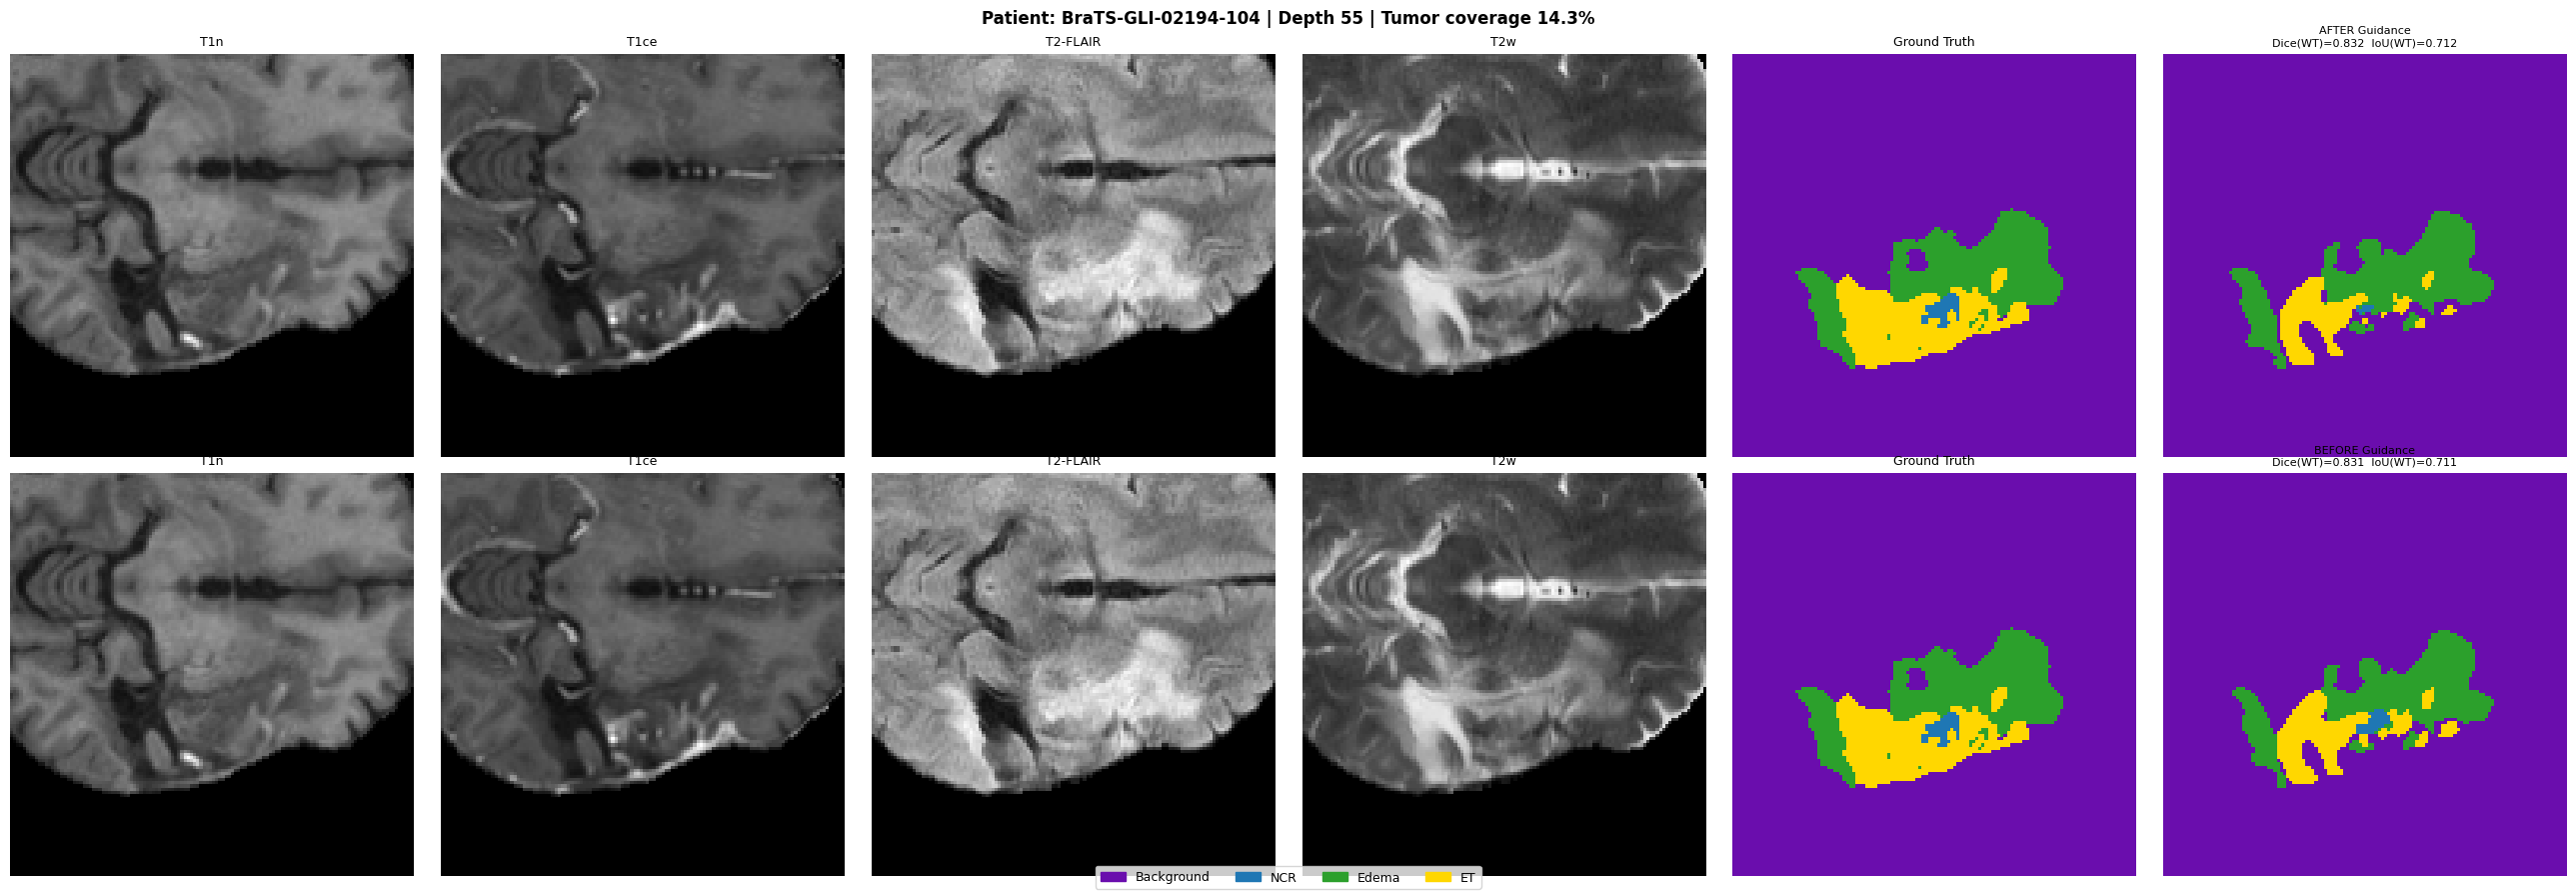

Evaluating:  12%|█▎        | 5/40 [00:25<02:49,  4.83s/it]

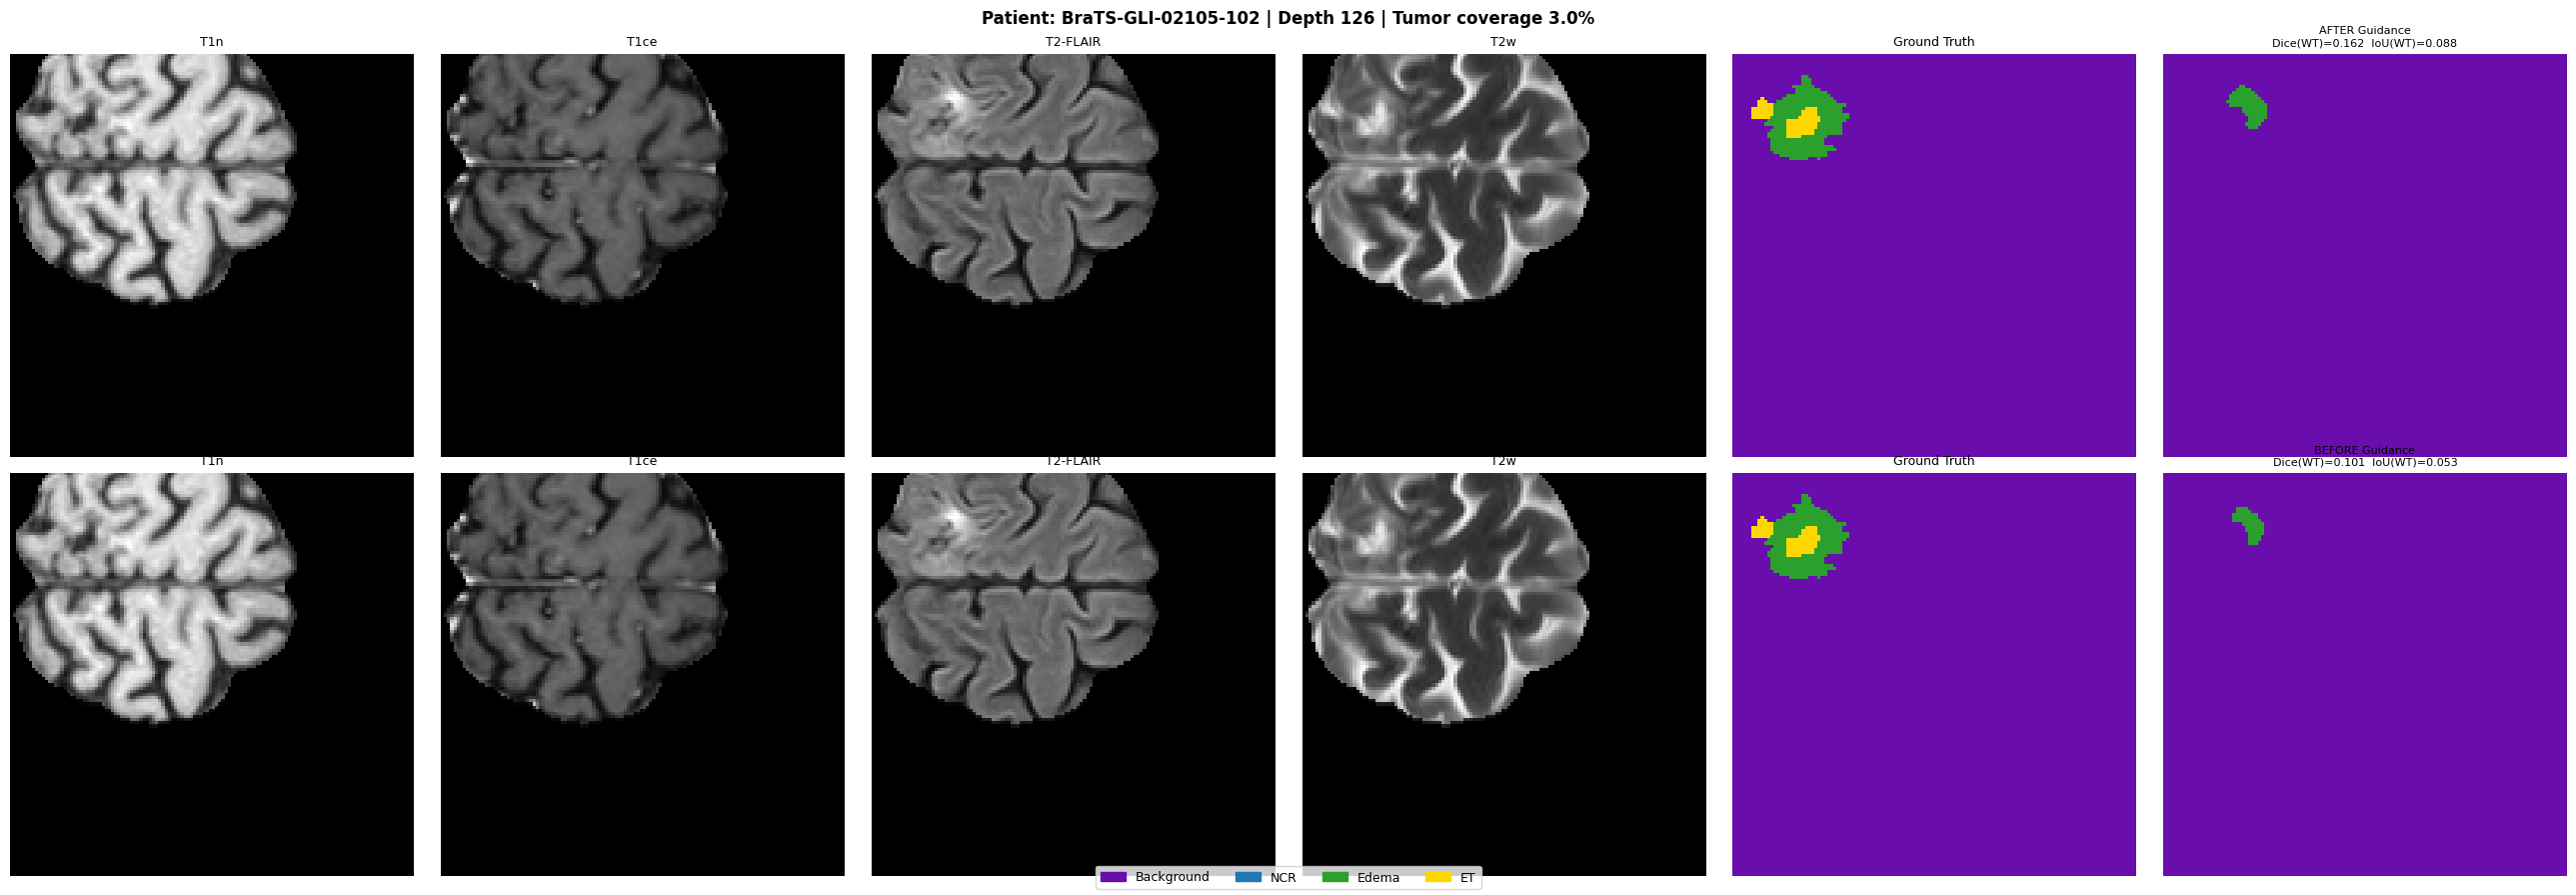

Evaluating:  25%|██▌       | 10/40 [00:47<02:08,  4.27s/it]

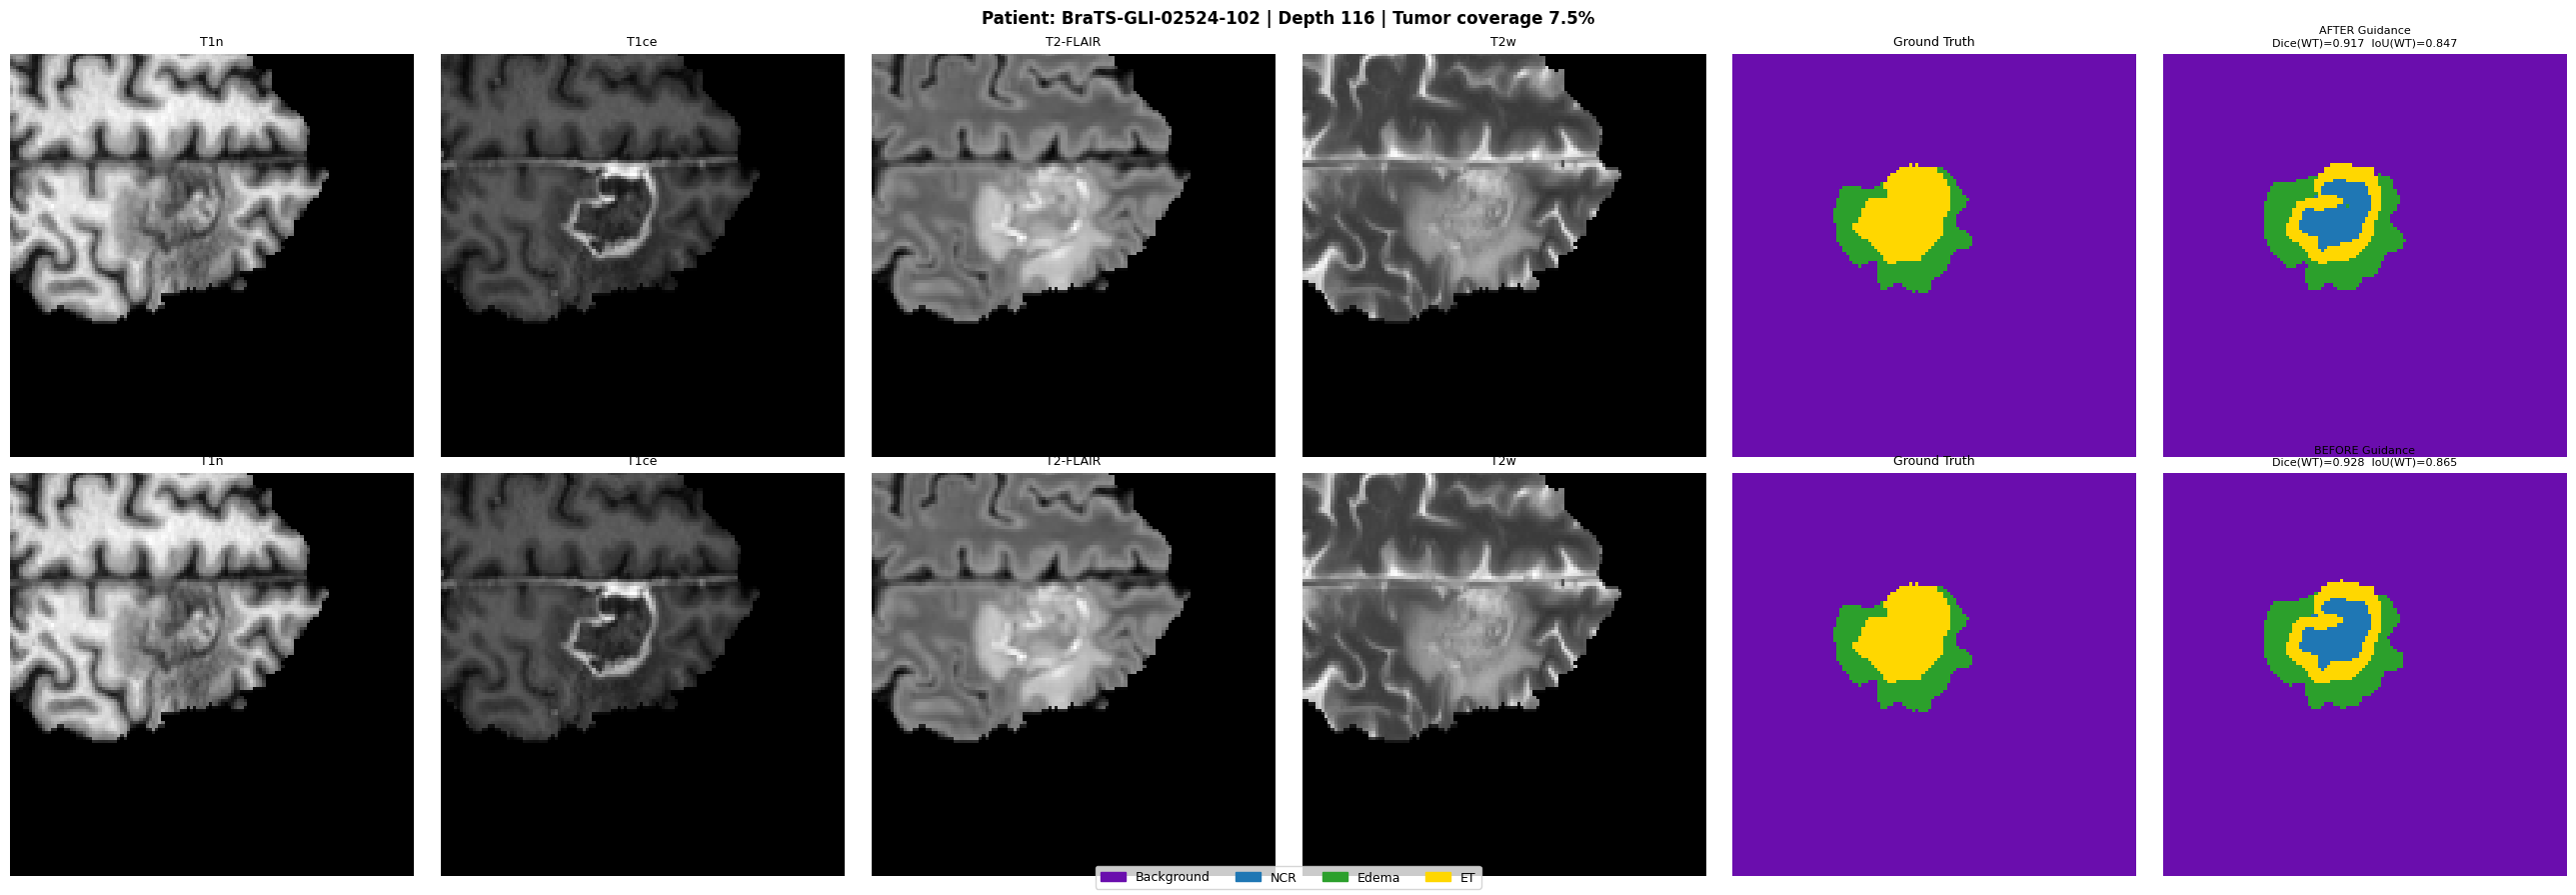

Evaluating:  38%|███▊      | 15/40 [01:08<01:40,  4.00s/it]

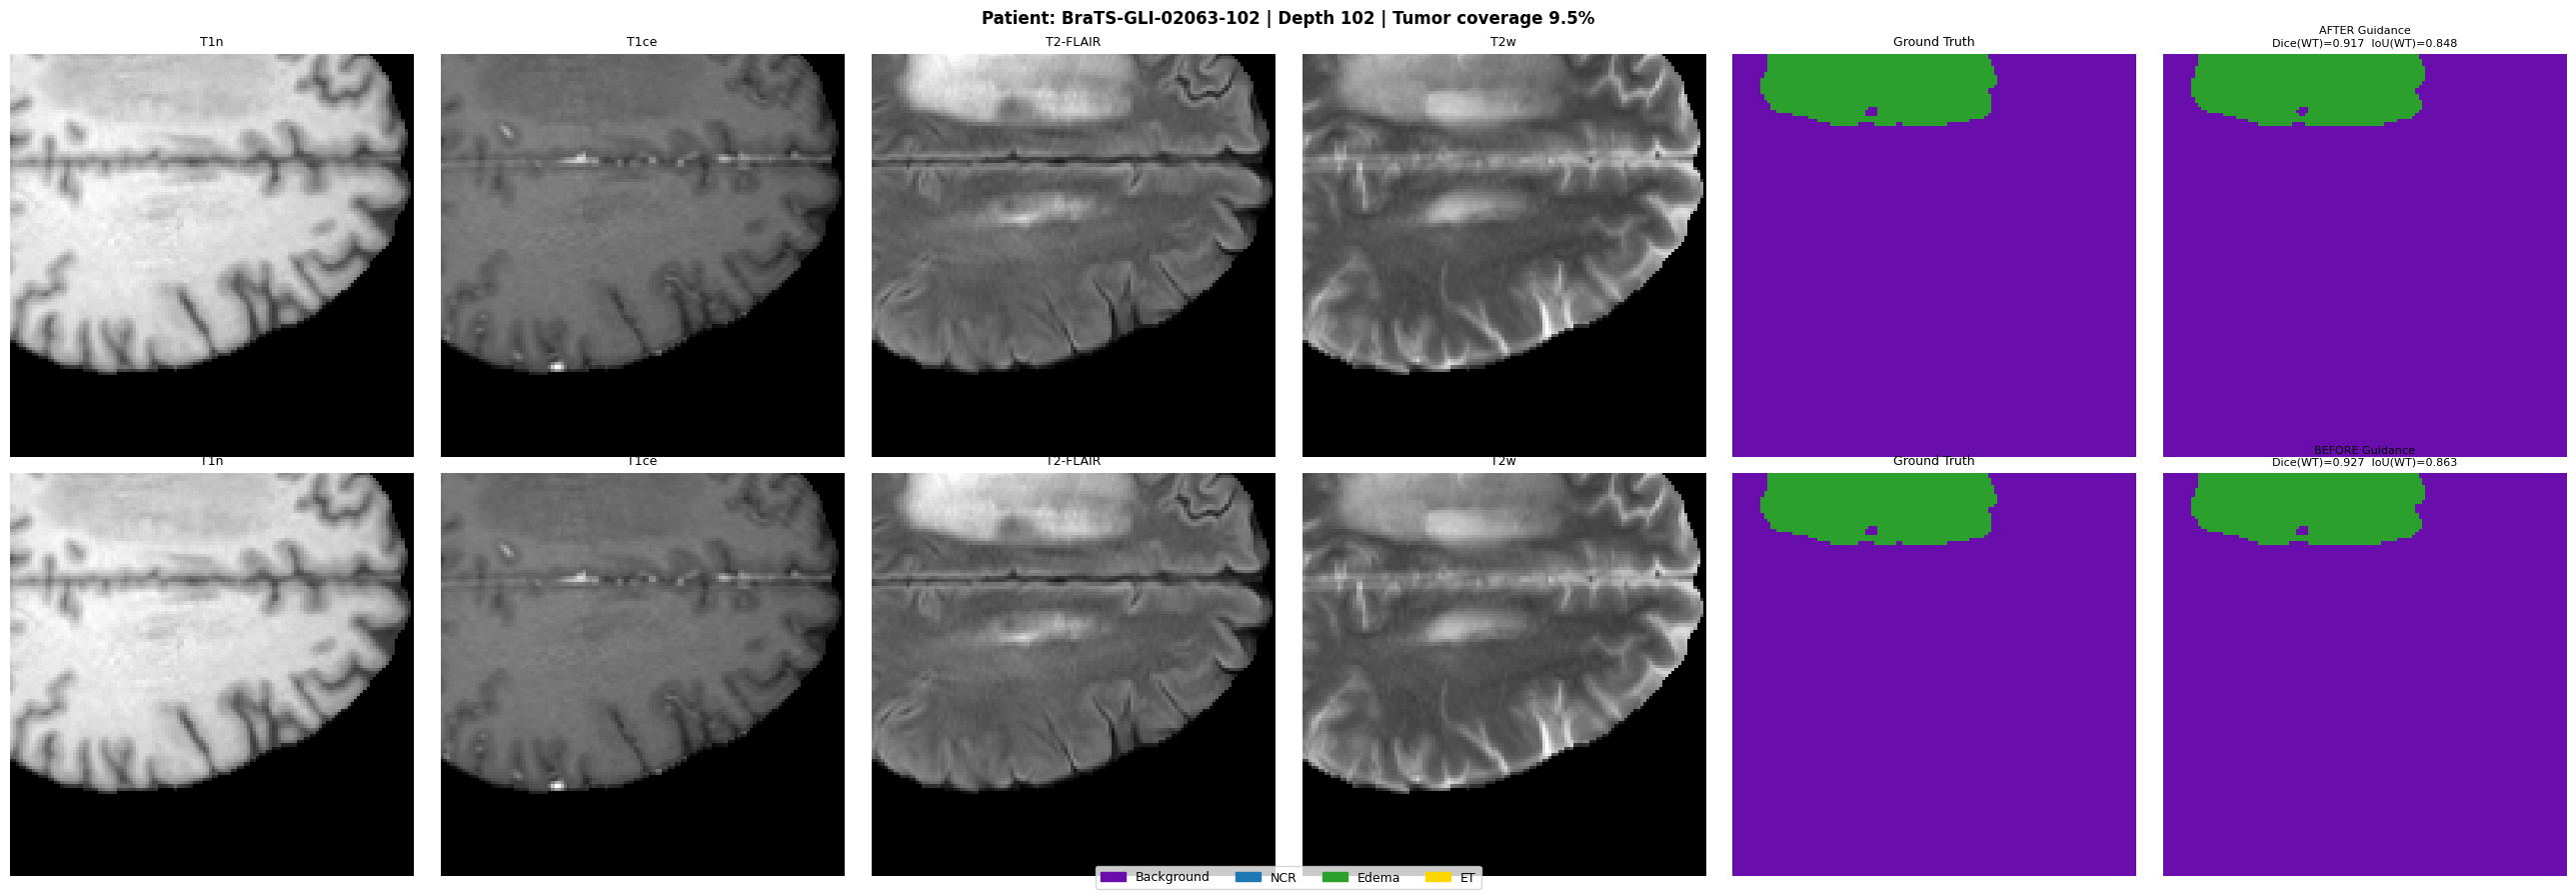

Evaluating:  50%|█████     | 20/40 [01:32<01:29,  4.46s/it]

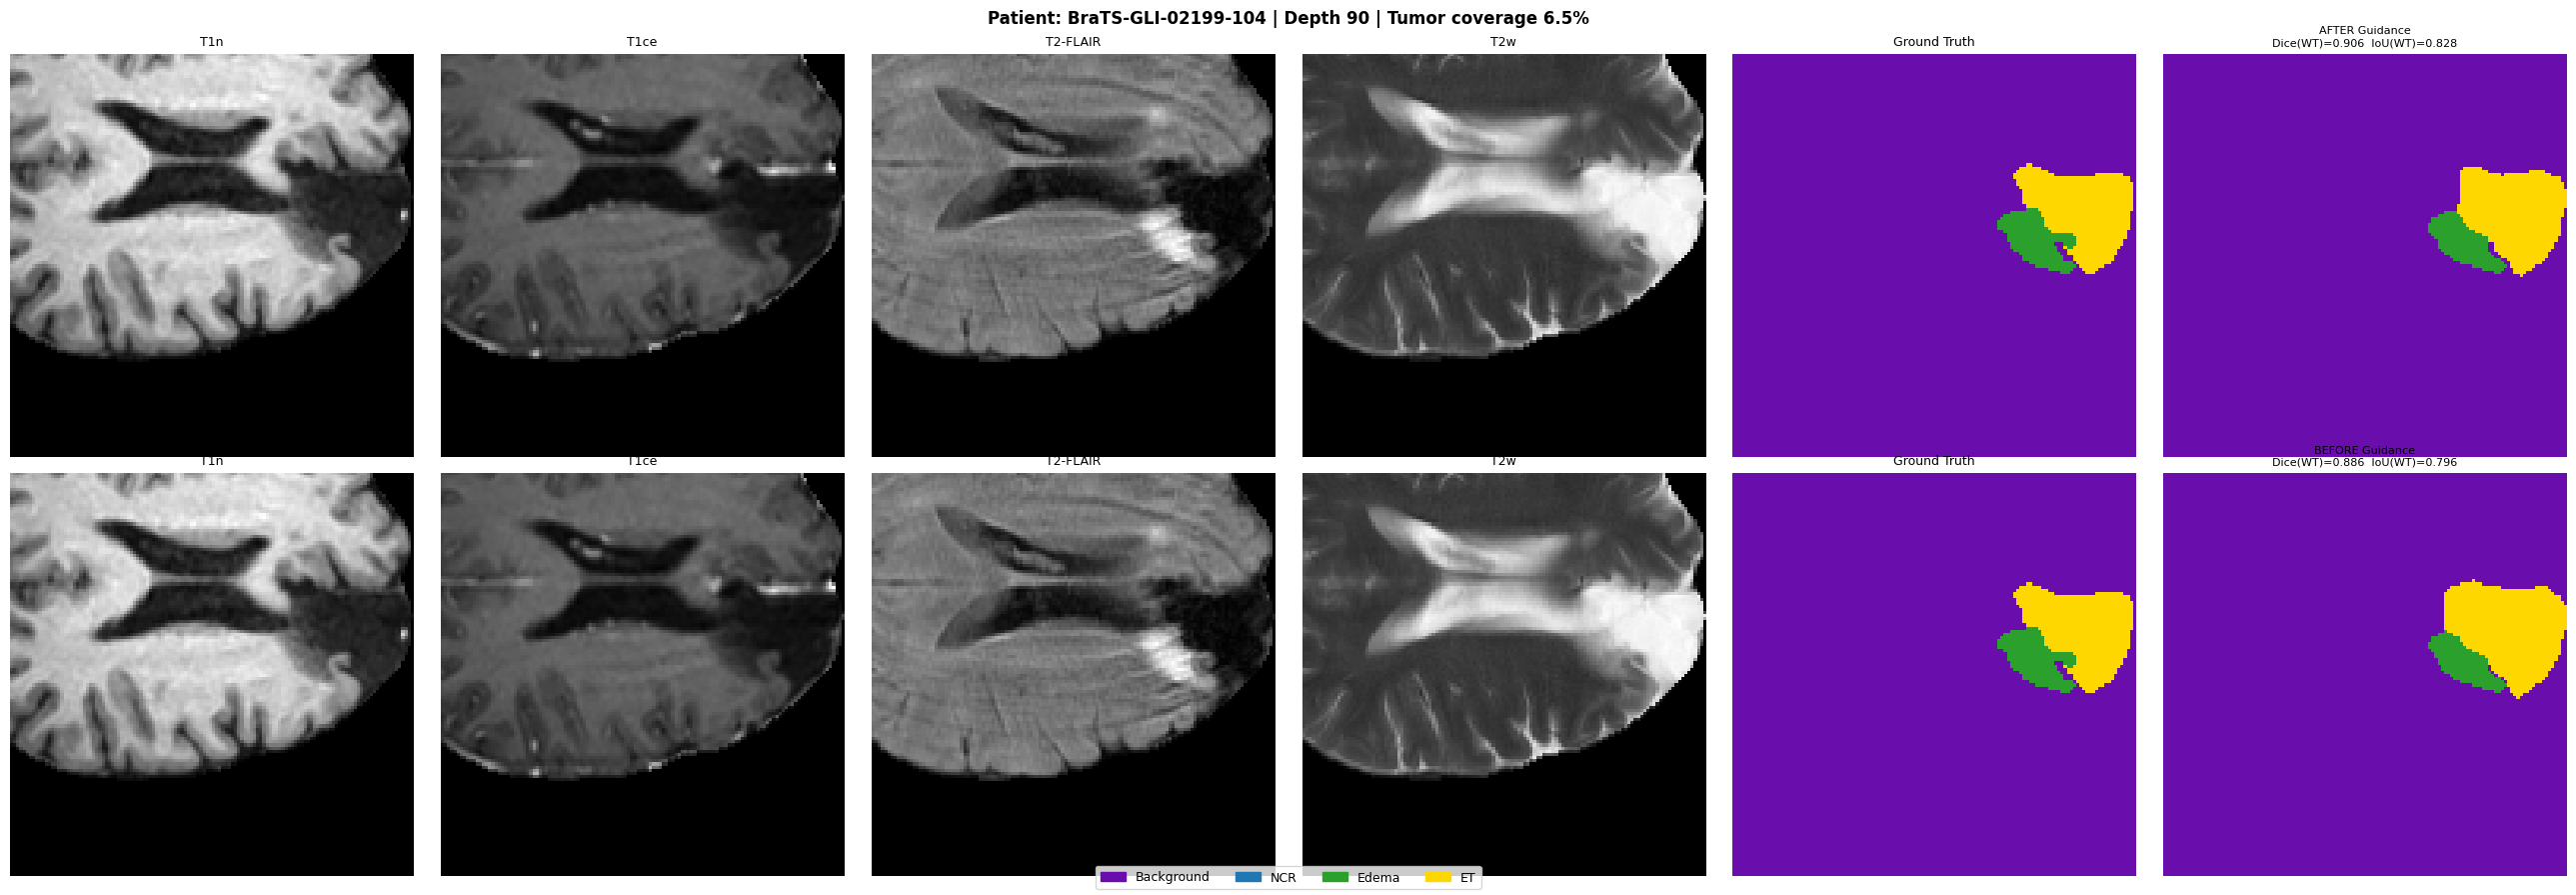

Evaluating:  62%|██████▎   | 25/40 [01:57<01:09,  4.62s/it]

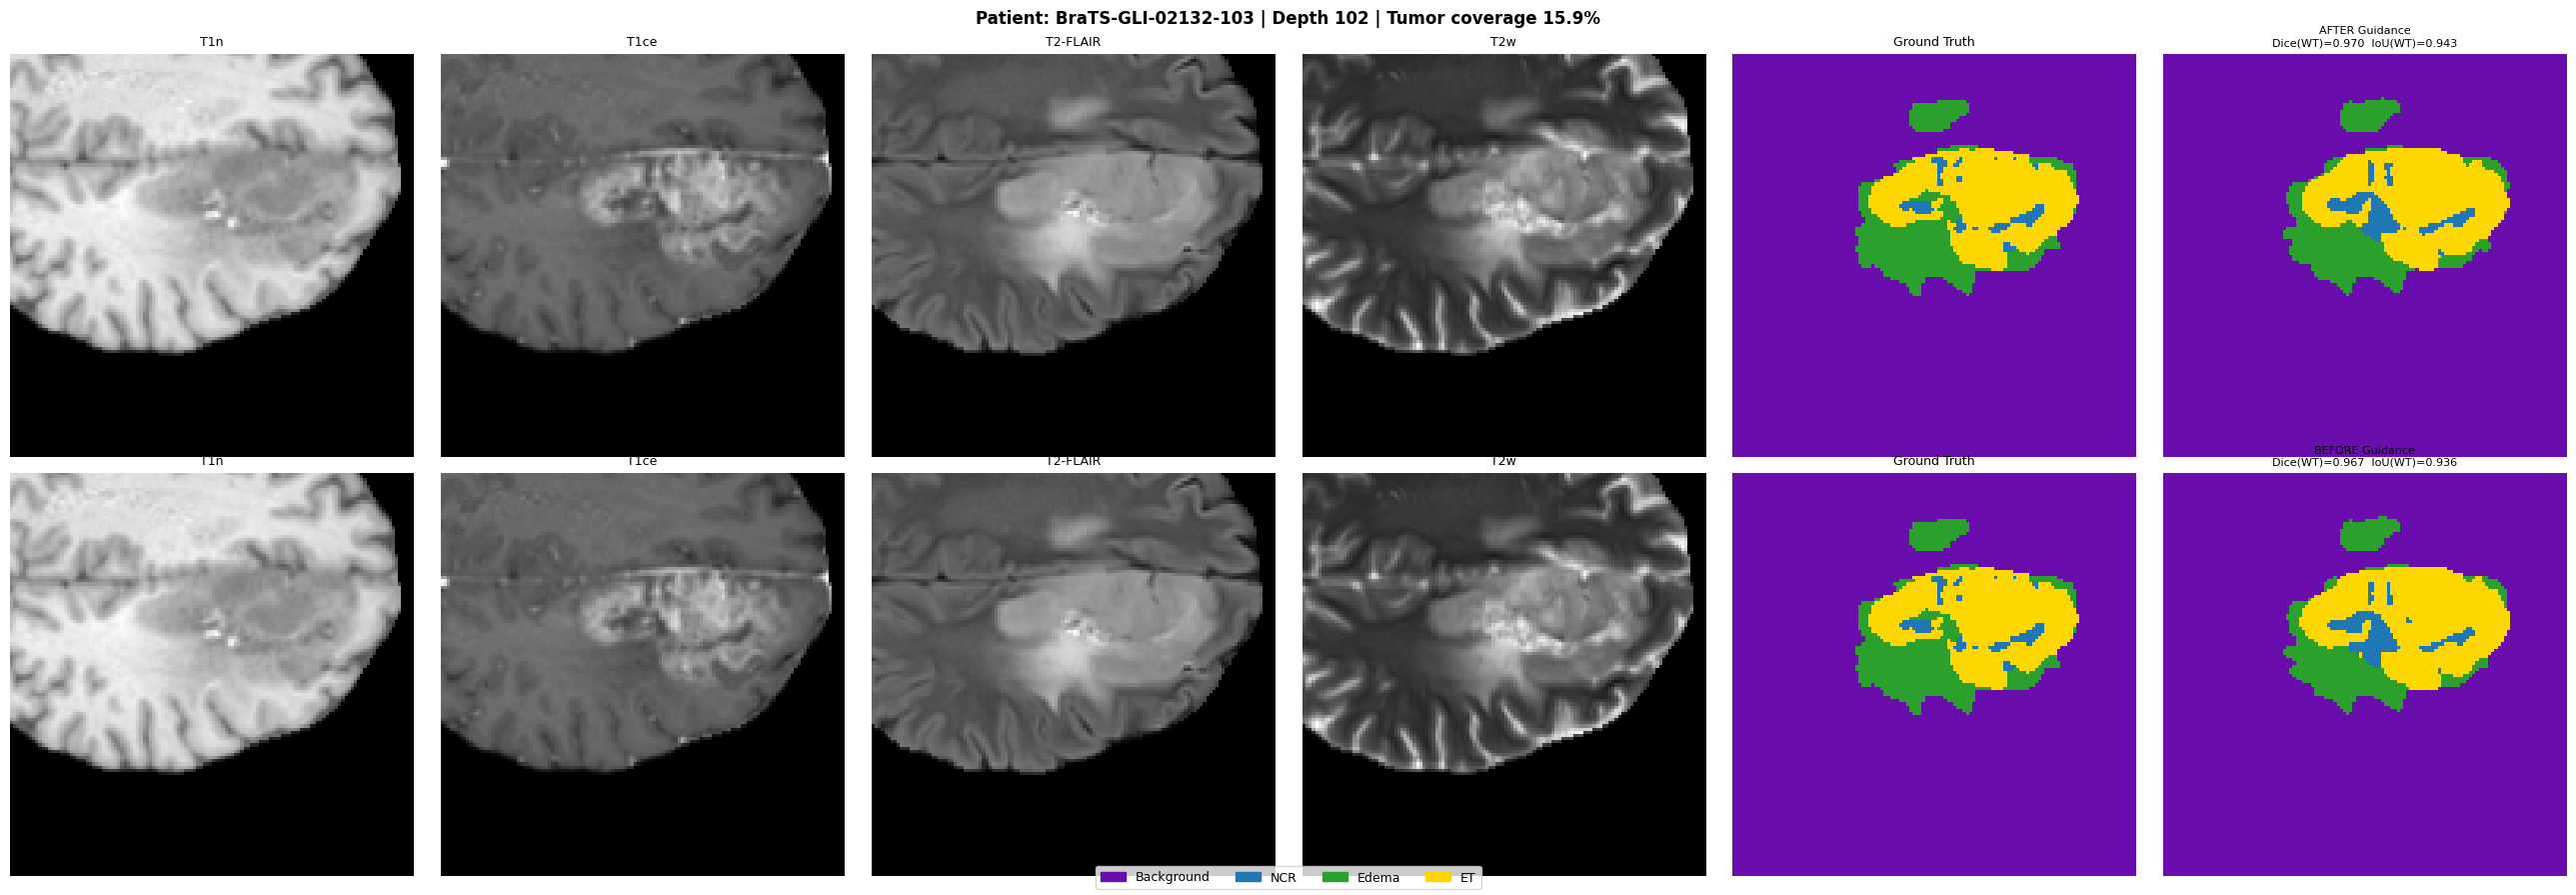

Evaluating:  75%|███████▌  | 30/40 [02:22<00:46,  4.65s/it]

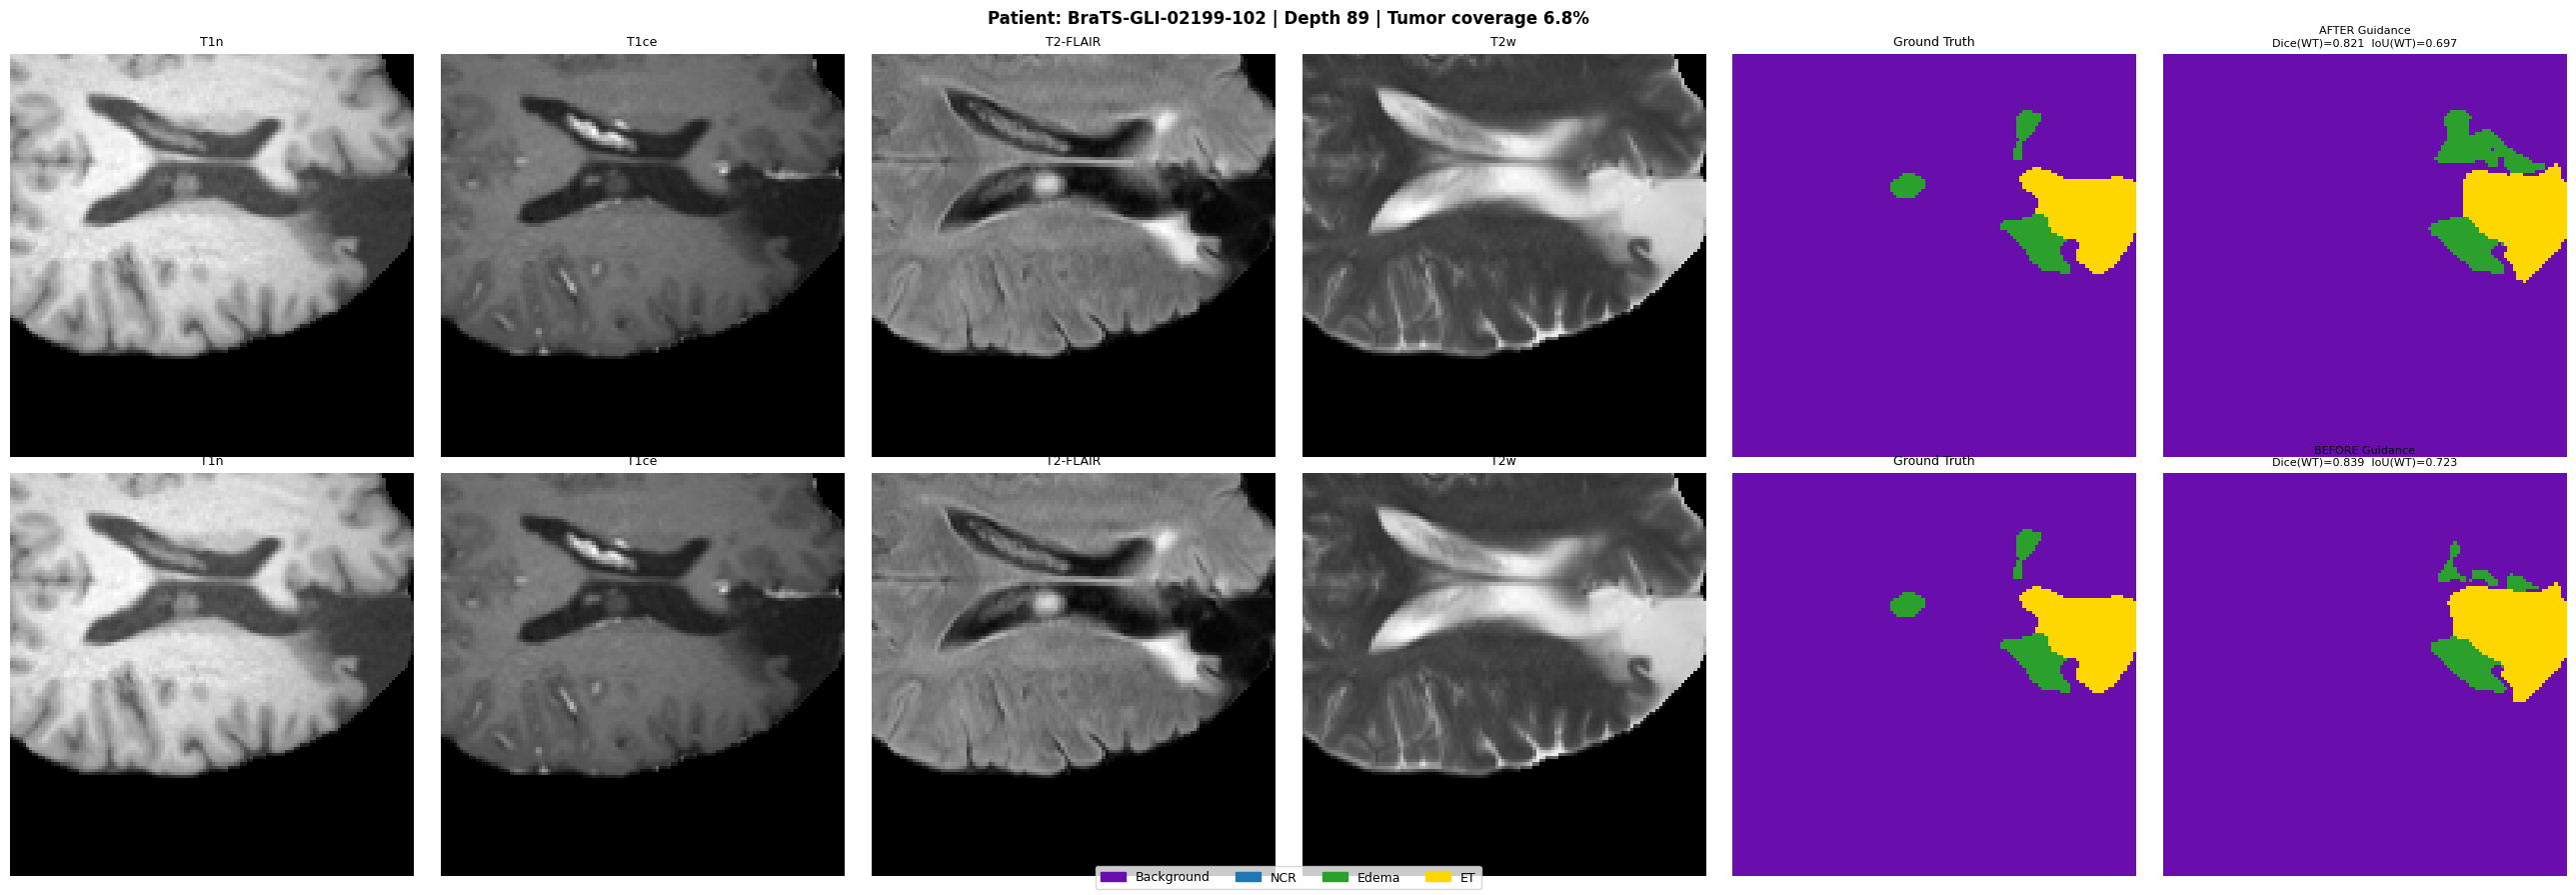

Evaluating:  88%|████████▊ | 35/40 [02:46<00:24,  4.86s/it]

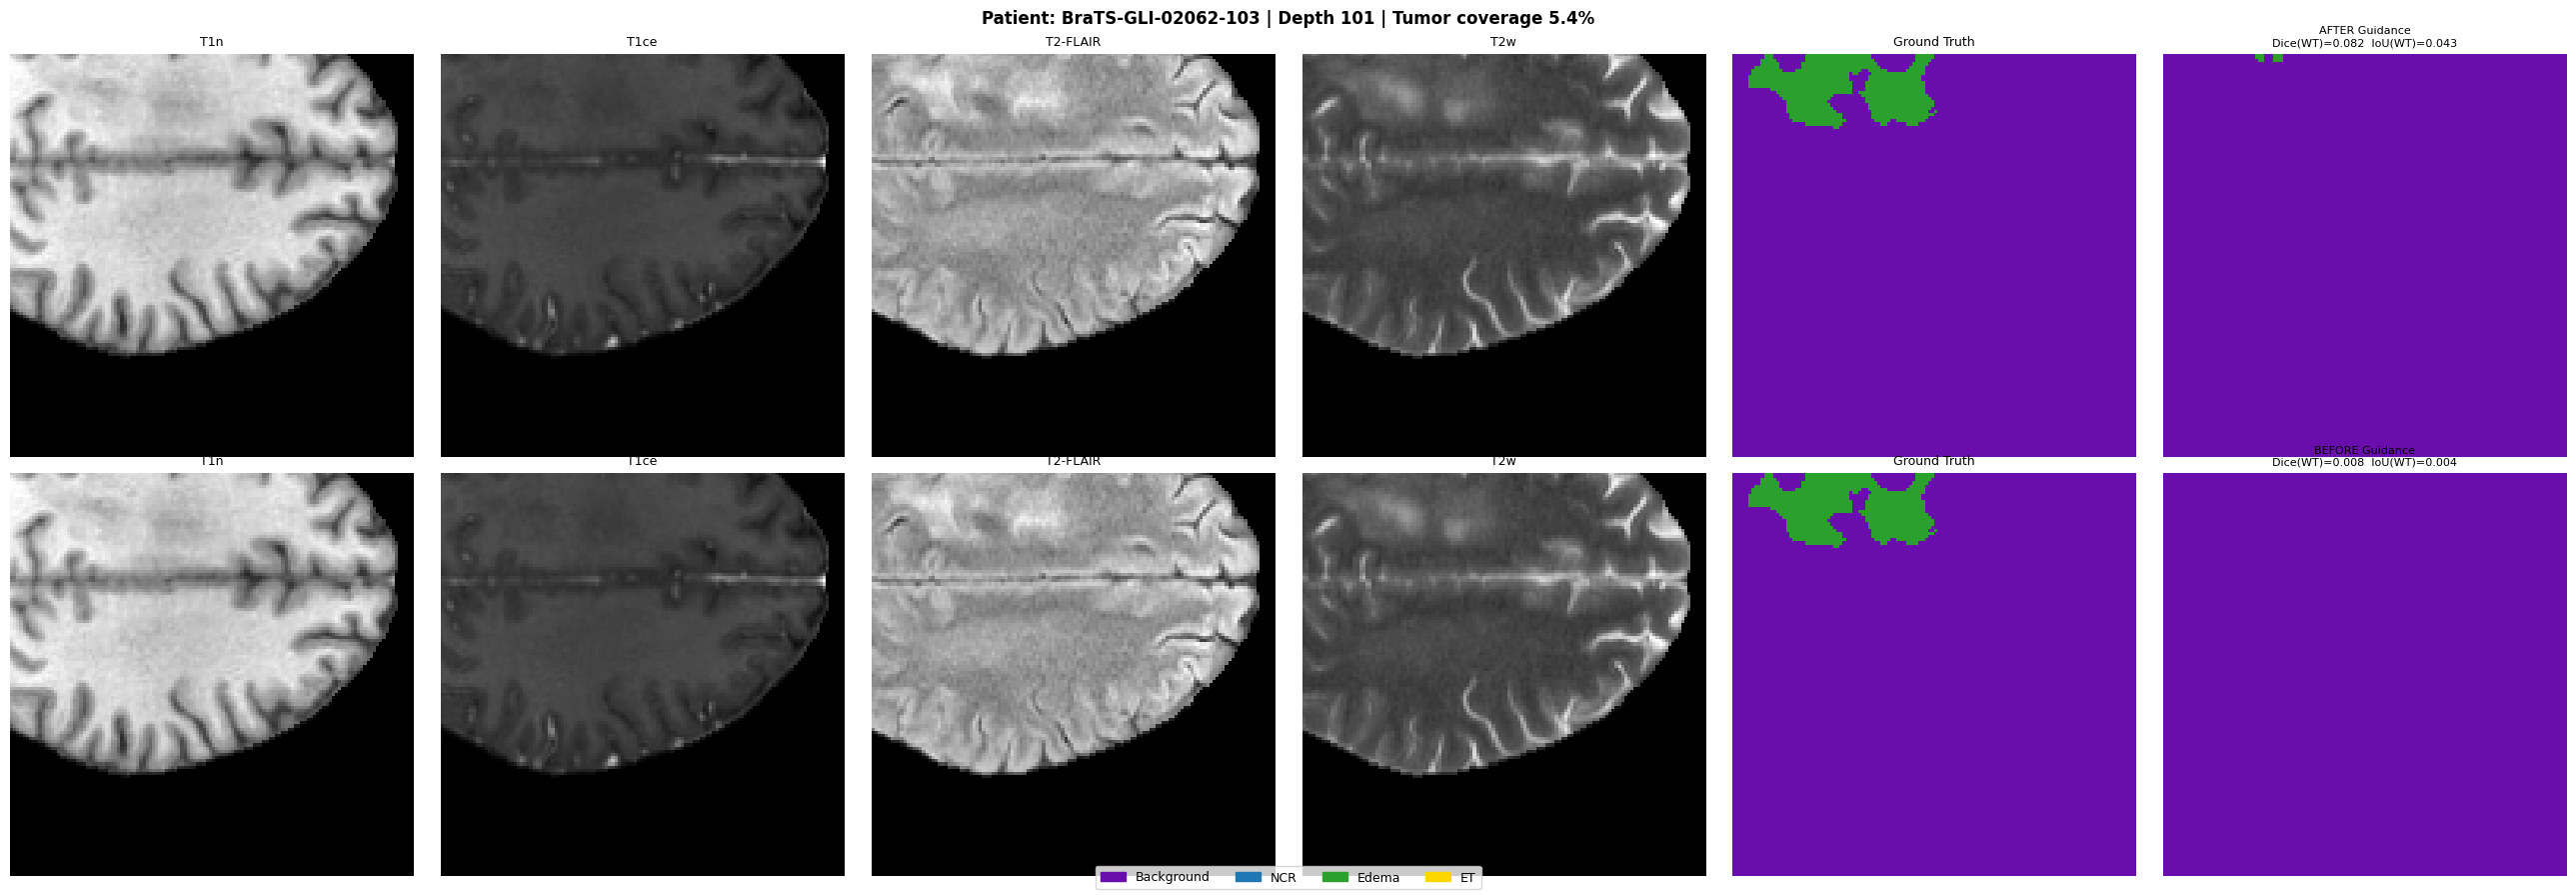

Evaluating: 100%|██████████| 40/40 [03:08<00:00,  4.72s/it]


✓ Evaluation complete — 40 patients
  all_metrics_before : 40 entries
  all_metrics_after  : 40 entries


In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# STEP 5 — RUN EVALUATION (CORRECTED)
# ════════════════════════════════════════════════════════════════════════════
def predict_before(vol_tensor):
    """
    Pure pretrained 3D U-Net — NO guidance injection at all.
    vol_tensor: (1, 4, 128, 128, 128) on DEVICE
    """
    with torch.no_grad():
        # Use standard forward pass — no injection
        seg_out, _ = model_before(vol_tensor)
    return seg_out.argmax(dim=1).cpu().numpy()[0]  # (128, 128, 128)


def predict_after(vol_tensor):
    """
    Guided fine-tuned 3D U-Net WITH guidance injection.
    vol_tensor: (1, 4, 128, 128, 128) on DEVICE
    """
    with torch.no_grad():
        e1  = model_after.enc1(vol_tensor)
        p1  = model_after.pool1(e1)
        e2a = model_after.enc2a(p1);   e2b = model_after.enc2b(e2a)
        p2  = model_after.pool2(e2b)
        e3a = model_after.enc3a(p2);   e3b = model_after.enc3b(e3a)
        p3  = model_after.pool3(e3b)
        bottleneck = model_after.bottleneck(p3)

        # Inject guidance
        g          = guidance_mean.expand(1, -1, -1, -1, -1)
        bottleneck = inject_after(torch.cat([bottleneck, g], dim=1))

        d1 = model_after.up1(bottleneck)
        if d1.shape[2:] != e3b.shape[2:]:
            d1 = F.interpolate(d1, size=e3b.shape[2:],
                               mode='trilinear', align_corners=False)
        d1 = model_after.dec1(torch.cat([d1, e3b], dim=1))

        d2 = model_after.up2(d1)
        if d2.shape[2:] != e2b.shape[2:]:
            d2 = F.interpolate(d2, size=e2b.shape[2:],
                               mode='trilinear', align_corners=False)
        d2 = model_after.dec2(torch.cat([d2, e2b], dim=1))

        d3 = model_after.up3(d2)
        if d3.shape[2:] != e1.shape[2:]:
            d3 = F.interpolate(d3, size=e1.shape[2:],
                               mode='trilinear', align_corners=False)
        d3 = model_after.dec3(torch.cat([d3, e1], dim=1))

        skip_in = model_after.input_skip(vol_tensor)
        if skip_in.shape[2:] != d3.shape[2:]:
            skip_in = F.interpolate(skip_in, size=d3.shape[2:],
                                    mode='trilinear', align_corners=False)

        seg_out = model_after.seg_head(torch.cat([d3, skip_in], dim=1))

    return seg_out.argmax(dim=1).cpu().numpy()[0]  # (128, 128, 128)


def find_best_tumor_slice(gt_vol):
    counts = (gt_vol > 0).sum(axis=(1, 2))
    ranked = np.argsort(counts)[::-1]
    valid  = [z for z in ranked if counts[z] > 50]
    return valid[0] if valid else int(np.argmax(counts))


# ── Reset metric lists ────────────────────────────────────────────────────────
all_metrics_before = []
all_metrics_after  = []

print(f"Running evaluation on {len(test_data)} test patients...")
print("=" * 60)

for idx, patient in enumerate(tqdm(test_data, desc="Evaluating")):
    pid   = patient['pid']
    image = patient['image']
    gt    = patient['seg']

    # Prepare tensor
    vol_t = torch.from_numpy(image).permute(3, 2, 0, 1).float()
    if vol_t.shape[1:] != (128, 128, 128):
        vol_t = F.interpolate(vol_t.unsqueeze(0), size=(128,128,128),
                              mode='trilinear', align_corners=False).squeeze(0)
    mean_v = vol_t.mean(dim=(1,2,3), keepdim=True)
    std_v  = vol_t.std(dim=(1,2,3),  keepdim=True).clamp(min=1e-6)
    vol_t  = ((vol_t - mean_v) / std_v).unsqueeze(0).to(DEVICE)

    # GT
    gt_t = torch.from_numpy(gt).permute(2, 0, 1).long()
    if gt_t.shape != (128, 128, 128):
        gt_t = F.interpolate(
            gt_t.float().unsqueeze(0).unsqueeze(0),
            size=(128,128,128), mode='nearest'
        ).squeeze().long()
    gt_np = gt_t.numpy()

    # Predict separately using dedicated functions
    pred_b = predict_before(vol_t)   # pure pretrained — no guidance
    pred_a = predict_after(vol_t)    # guided fine-tuned — with guidance

    # Verify predictions are different for first patient
    if idx == 0:
        diff = (pred_b != pred_a).sum()
        total = pred_b.size
        print(f"\n✓ Prediction difference check (patient 0):")
        print(f"  Voxels where before != after : {diff} / {total} "
              f"({diff/total*100:.2f}%)")
        if diff == 0:
            print("  ⚠ WARNING: Both models produce identical predictions!")
            print("  Check that model weights are actually different.")
        else:
            print("  ✓ Models are producing different predictions — correct")

    # Compute metrics
    m_b = compute_all_metrics(pred_b, gt_np)
    m_a = compute_all_metrics(pred_a, gt_np)

    all_metrics_before.append(m_b)
    all_metrics_after.append(m_a)

    # Visualization every 5th patient
    if idx % 5 == 0:
        z       = find_best_tumor_slice(gt_np)
        imgs_np = vol_t.cpu().numpy()[0]
        tumor_frac = (gt_np[z] > 0).mean() * 100

        fig, axes = plt.subplots(2, 6, figsize=(26, 9))
        fig.suptitle(
            f"Patient: {pid} | Depth {z} | Tumor coverage {tumor_frac:.1f}%",
            fontsize=12, fontweight='bold'
        )

        for ch, title in enumerate(["T1n", "T1ce", "T2-FLAIR", "T2w"]):
            axes[0, ch].imshow(imgs_np[ch, z], cmap='gray')
            axes[0, ch].set_title(title, fontsize=9)
            axes[0, ch].axis('off')
            axes[1, ch].imshow(imgs_np[ch, z], cmap='gray')
            axes[1, ch].set_title(title, fontsize=9)
            axes[1, ch].axis('off')

        axes[0, 4].imshow(gt_np[z], cmap=cmap, vmin=0, vmax=3)
        axes[0, 4].set_title("Ground Truth", fontsize=9)
        axes[0, 4].axis('off')
        axes[0, 5].imshow(pred_b[z], cmap=cmap, vmin=0, vmax=3)
        axes[0, 5].set_title(
            f"AFTER Guidance\n"
            f"Dice(WT)={m_b['WT']['dice']:.3f}  "
            f"IoU(WT)={m_b['WT']['iou']:.3f}",
            fontsize=8
        )
        axes[0, 5].axis('off')
        axes[0, 0].set_ylabel("AFTER\nGuidance", fontsize=10,
                               fontweight='bold', color='tomato')

        axes[1, 4].imshow(gt_np[z], cmap=cmap, vmin=0, vmax=3)
        axes[1, 4].set_title("Ground Truth", fontsize=9)
        axes[1, 4].axis('off')
        axes[1, 5].imshow(pred_a[z], cmap=cmap, vmin=0, vmax=3)
        axes[1, 5].set_title(
            f"BEFORE Guidance\n"
            f"Dice(WT)={m_a['WT']['dice']:.3f}  "
            f"IoU(WT)={m_a['WT']['iou']:.3f}",
            fontsize=8
        )
        axes[1, 5].axis('off')
        axes[1, 0].set_ylabel("BEFORE\nGuidance", fontsize=10,
                               fontweight='bold', color='steelblue')

        patches = [mpatches.Patch(color=c, label=n)
                   for c, n in zip(CLASS_COLORS, CLASS_NAMES)]
        fig.legend(handles=patches, loc='lower center',
                   ncol=4, fontsize=9, framealpha=0.8)
        plt.tight_layout()
        plt.savefig(
            os.path.join(RESULTS_DIR, f'eval_unet_{pid}_z{z}.png'),
            dpi=120, bbox_inches='tight'
        )
        plt.show()
        plt.close()

    del vol_t
    torch.cuda.empty_cache()

print(f"\n✓ Evaluation complete — {len(test_data)} patients")
print(f"  all_metrics_before : {len(all_metrics_before)} entries")
print(f"  all_metrics_after  : {len(all_metrics_after)} entries")

In [ ]:
# ════════════════════════════════════════════════════════════════════════════
# STEP 6 — AGGREGATE RESULTS AND PRINT SUMMARY TABLE
# ════════════════════════════════════════════════════════════════════════════
regions  = ['WT', 'TC', 'ET', 'NCR', 'Edema']
metrics  = ['dice', 'iou', 'precision', 'recall', 'hd95']

def aggregate(all_metrics, region, metric):
    vals = [m[region][metric] for m in all_metrics
            if region in m and metric in m[region]]
    return np.mean(vals), np.std(vals)

print("\n" + "="*80)
print(" 3D U-NET EVALUATION RESULTS — 40 HELD-OUT TEST PATIENTS")
print("="*80)
print(f"\n{'Region':<10} {'Metric':<12} {'AFTER Guidance':>18} {'BEFORE Guidance':>18} {'Change':>10}")
print("-"*70)

summary = {}
for region in regions:
    for metric in metrics:
        b_mean, b_std = aggregate(all_metrics_after, region, metric)
        a_mean, a_std = aggregate(all_metrics_before,  region, metric)
        change        = a_mean - b_mean
        arrow         = "↑" if (change > 0 and metric != 'hd95') or \
                                (change < 0 and metric == 'hd95') else "↓"
        # a_mean printed under BEFORE column, b_mean printed under AFTER column
        print(f"{region:<10} {metric:<12} "
              f"{b_mean:>8.4f}±{b_std:.4f}  "
              f"{a_mean:>8.4f}±{a_std:.4f}  "
              f"{arrow}{abs(change):>8.4f}")
        summary[(region, metric)] = (a_mean, a_std, b_mean, b_std)
    print()

print("="*80)

# Save summary to text file
summary_path = os.path.join(RESULTS_DIR, 'unet_evaluation_summary.txt')
with open(summary_path, 'w') as f:
    f.write("3D U-Net Evaluation — 40 Held-Out Test Patients\n")
    f.write("="*70 + "\n")
    f.write(f"{'Region':<10} {'Metric':<12} {'Before':>14} {'After':>14} {'Change':>10}\n")
    f.write("-"*70 + "\n")
    for region in regions:
        for metric in metrics:
            b_mean, b_std, a_mean, a_std = summary[(region, metric)]
            change = a_mean - b_mean
            f.write(f"{region:<10} {metric:<12} "
                    f"{b_mean:>8.4f}±{a_std:.4f}  "
                    f"{a_mean:>8.4f}±{b_std:.4f}  "
                    f"{change:>+8.4f}\n")
        f.write("\n")
print(f"\n✓ Summary saved → {summary_path}")


 3D U-NET EVALUATION RESULTS — 40 HELD-OUT TEST PATIENTS

Region     Metric           AFTER Guidance    BEFORE Guidance     Change
----------------------------------------------------------------------
WT         dice           0.7735±0.2831    0.7822±0.2706  ↑  0.0087
WT         iou            0.6933±0.2736    0.7010±0.2663  ↑  0.0078
WT         precision      0.8605±0.2334    0.8680±0.2110  ↑  0.0075
WT         recall         0.7685±0.2906    0.7847±0.2789  ↑  0.0162
WT         hd95          29.4631±80.9526   20.6874±59.5167  ↑  8.7757

TC         dice           0.5599±0.3712    0.5640±0.3821  ↑  0.0042
TC         iou            0.4761±0.3411    0.4839±0.3444  ↑  0.0078
TC         precision      0.6346±0.3549    0.6939±0.3901  ↑  0.0593
TC         recall         0.6187±0.3962    0.5655±0.3798  ↓  0.0532
TC         hd95          61.0715±119.3844   76.1051±137.6365  ↓ 15.0336

ET         dice           0.5611±0.3700    0.5657±0.3755  ↑  0.0046
ET         iou            0.4766±0.3395  

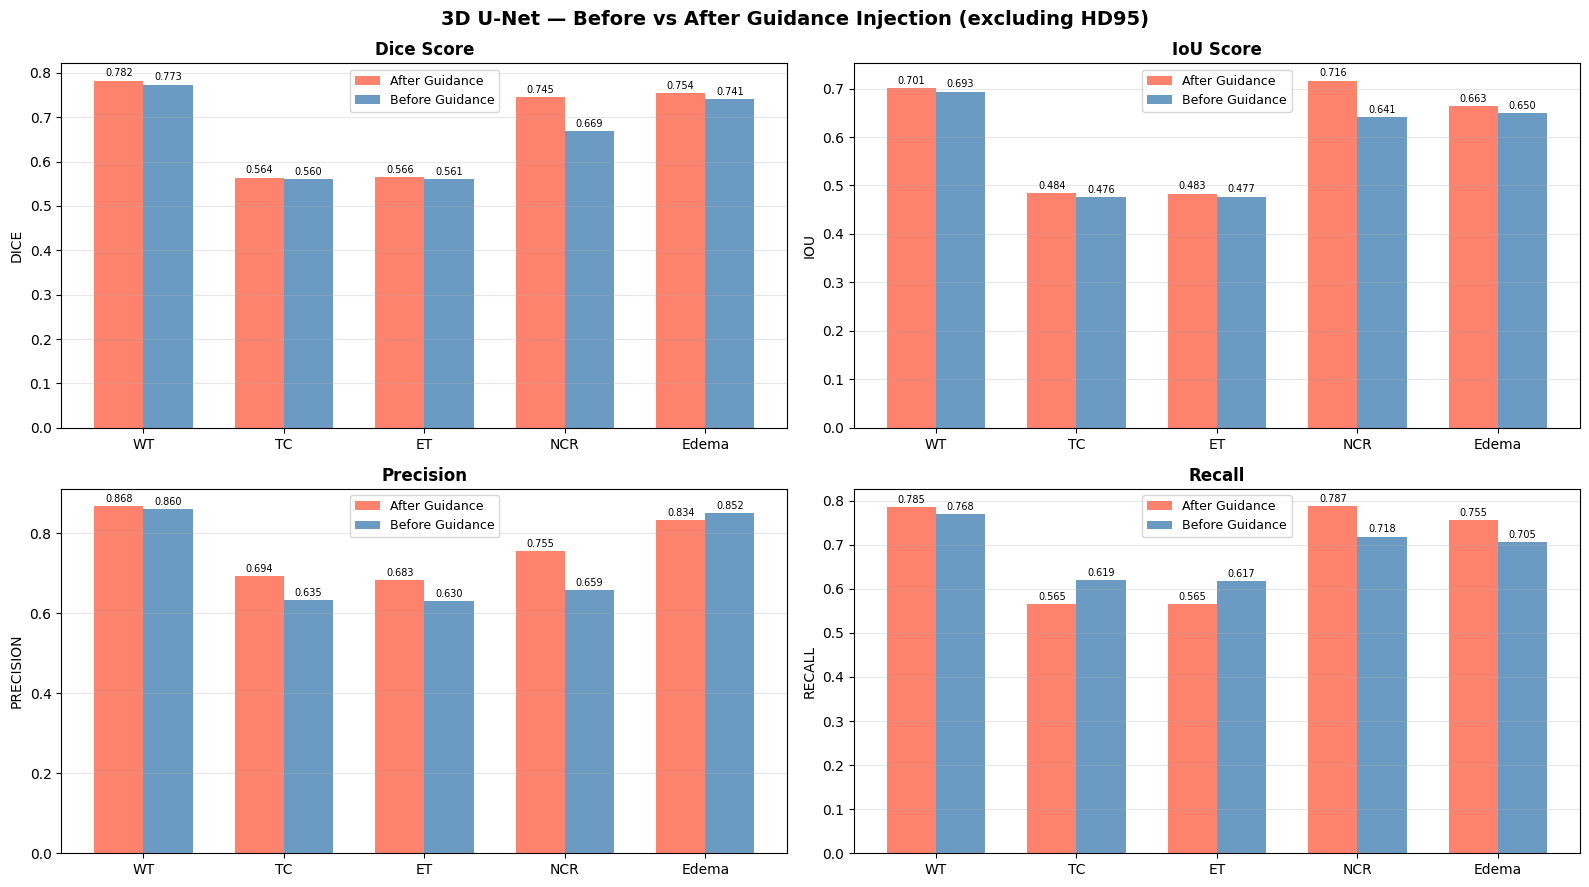

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# STEP 7 — PLOT METRIC COMPARISON CHARTS (excluding HD95)
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
fig, axes = plt.subplots(2, 2, figsize=(16, 9)) # Changed to 2x2 for 4 plots
axes = axes.flatten()

plot_metrics = ['dice', 'iou', 'precision', 'recall'] # Exclude 'hd95'
plot_titles  = ['Dice Score', 'IoU Score', 'Precision', 'Recall'] # Exclude 'HD95 (lower=better)'

for ax_idx, (metric, title) in enumerate(zip(plot_metrics, plot_titles)):
    before_vals = [aggregate(all_metrics_before, r, metric)[0] for r in regions]
    after_vals  = [aggregate(all_metrics_after,  r, metric)[0] for r in regions]

    x     = np.arange(len(regions))
    width = 0.35

    ax = axes[ax_idx] # Moved this line to ensure 'ax' is defined
    bars_b = ax.bar(x - width/2, before_vals, width,
                    label='After Guidance', color='tomato', alpha=0.8)
    bars_a = ax.bar(x + width/2, after_vals,  width,
                    label='Before Guidance',  color='steelblue', alpha=0.8)

    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(regions, fontsize=10)
    ax.set_ylabel(metric.upper(), fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3, axis='y')

    # Value labels on bars
    for bar in bars_b:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=7)
    for bar in bars_a:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=7)



plt.suptitle("3D U-Net — Before vs After Guidance Injection (excluding HD95)",
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'unet_metric_comparison_no_hd95.png'),
            dpi=150, bbox_inches='tight')
plt.show()



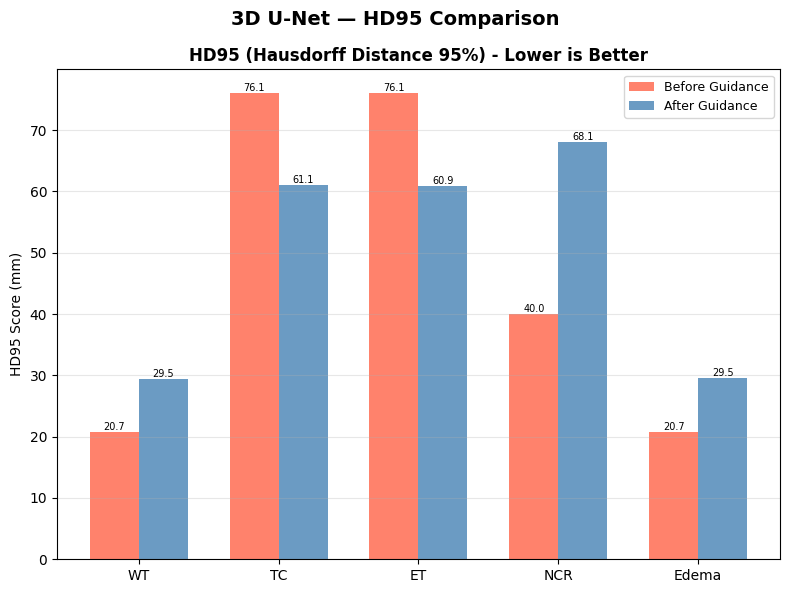

✓ HD95 comparison chart saved


In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np

# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
# STEP 8 — PLOT HD95 METRIC SEPARATELY
# ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

fig_hd95, ax_hd95 = plt.subplots(1, 1, figsize=(8, 6))

hd95_before_vals = [aggregate(all_metrics_before, r, 'hd95')[0] for r in regions]
hd95_after_vals  = [aggregate(all_metrics_after,  r, 'hd95')[0] for r in regions]

x     = np.arange(len(regions))
width = 0.35

bars_b_hd95 = ax_hd95.bar(x - width/2, hd95_before_vals, width,
                        label='Before Guidance', color='tomato', alpha=0.8)
bars_a_hd95 = ax_hd95.bar(x + width/2, hd95_after_vals,  width,
                        label='After Guidance',  color='steelblue', alpha=0.8)

ax_hd95.set_title('HD95 (Hausdorff Distance 95%) - Lower is Better', fontsize=12, fontweight='bold')
ax_hd95.set_xticks(x)
ax_hd95.set_xticklabels(regions, fontsize=10)
ax_hd95.set_ylabel('HD95 Score (mm)', fontsize=10)
ax_hd95.legend(fontsize=9)
ax_hd95.grid(True, alpha=0.3, axis='y')

# Value labels on bars
for bar in bars_b_hd95:
    ax_hd95.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=7)
for bar in bars_a_hd95:
    ax_hd95.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.1f}', ha='center', va='bottom', fontsize=7)

plt.suptitle("3D U-Net — HD95 Comparison", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'unet_metric_comparison_hd95.png'),
            dpi=150, bbox_inches='tight')
plt.show()
print(f"✓ HD95 comparison chart saved")

**ROUND 3**

In [ ]:
import gdown, os, torch, gc
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from tqdm import tqdm
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR
from segmentation_models_pytorch import losses as smp_losses

DRIVE_BASE     = '/content/drive/MyDrive/BraTS2024_3DUNet'
DRIVE_CKPT_DIR = os.path.join(DRIVE_BASE, 'checkpoints')
GUIDANCE_R2    = os.path.join(DRIVE_BASE, 'guidance_round2.pt')
ROUND2_CKPT    = os.path.join(DRIVE_CKPT_DIR, 'round2_ckpt.tar')
ROUND3_CKPT    = os.path.join(DRIVE_CKPT_DIR, 'round3_ckpt.tar')

# Download guidance_round2.pt
if not os.path.exists(GUIDANCE_R2):
    print("Downloading guidance_round2.pt...")
    gdown.download(
        "https://drive.google.com/uc?id=15j15bO9iOLKZ_aulOZDSePuXPkAVFS7y",
        GUIDANCE_R2, quiet=False
    )
else:
    print(f"✓ guidance_round2.pt already exists")

guidance_r2      = torch.load(GUIDANCE_R2, map_location='cpu')
guidance_mean_r2 = guidance_r2.mean(dim=0, keepdim=True).to(DEVICE)
print(f"✓ guidance_round2.pt loaded")
print(f"  Shape : {guidance_r2.shape}")
print(f"  Mean  : {guidance_r2.mean():.4f}")
print(f"  Max   : {guidance_r2.max():.4f}")

Downloading...
From (original): https://drive.google.com/uc?id=15j15bO9iOLKZ_aulOZDSePuXPkAVFS7y
From (redirected): https://drive.google.com/uc?id=15j15bO9iOLKZ_aulOZDSePuXPkAVFS7y&confirm=t&uuid=01d1ac14-1922-4d3d-9128-4b41ac8f333f
To: /content/drive/MyDrive/BraTS2024_3DUNet/guidance_round2.pt
100%|██████████| 83.9M/83.9M [00:01<00:00, 51.7MB/s]

✓ guidance_round2.pt loaded
  Shape : torch.Size([20, 256, 16, 16, 16])
  Mean  : 0.1870
  Max   : 14.8999


In [ ]:
# ── Load Round 2 checkpoint as starting point ─────────────────────────────────
model_r3  = UNet3D_Heterogeneous(in_channels=4, num_classes=4).to(DEVICE)
inject_r3 = nn.Conv3d(512, 256, kernel_size=1, bias=False).to(DEVICE)

ckpt_r2 = torch.load(ROUND2_CKPT, map_location=DEVICE)
model_r3.load_state_dict(ckpt_r2['model'])
inject_r3.load_state_dict(ckpt_r2['guidance_inject'])
model_r3.eval()
inject_r3.eval()
print(f"✓ Loaded round2_ckpt.tar as Round 3 starting point")
print(f"  Epoch   : {ckpt_r2['epoch']}")
print(f"  Val IoU : {ckpt_r2['val_iou']:.4f}")
print(f"  Val Loss: {ckpt_r2['val_loss']:.4f}")

✓ Loaded round2_ckpt.tar as Round 3 starting point
  Epoch   : 9
  Val IoU : 0.6448
  Val Loss: 0.2667


In [ ]:
# ── Rebuild DataLoaders ────────────────────────────────────────────────────────
preproc_base  = CFG.PREPROCESSED_PATH
drive_preproc = os.path.join(DRIVE_BASE, 'preprocessed')

if not os.path.exists(os.path.join(preproc_base, 'train', 'images')):
    import shutil
    if os.path.exists(preproc_base):
        shutil.rmtree(preproc_base)
    shutil.copytree(drive_preproc, preproc_base)
    create_train_val_split(preproc_base, CFG.TRAIN_RATIO, CFG.RANDOM_SEED)
    print("✓ Preprocessed data restored from Drive")

train_ds = BraTS2024Dataset(
    os.path.join(preproc_base, 'train', 'images'),
    os.path.join(preproc_base, 'train', 'masks'),
)
val_ds = BraTS2024Dataset(
    os.path.join(preproc_base, 'val', 'images'),
    os.path.join(preproc_base, 'val', 'masks'),
)
train_loader = DataLoader(train_ds, batch_size=CFG.BATCH_SIZE, shuffle=True,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY, prefetch_factor=2)
val_loader = DataLoader(val_ds, batch_size=CFG.BATCH_SIZE, shuffle=False,
    num_workers=CFG.NUM_WORKERS, pin_memory=CFG.PIN_MEMORY)
print(f"✓ DataLoaders ready — Train: {len(train_ds)} | Val: {len(val_ds)}")

✓ Split — Train: 296 | Val: 99
✓ Preprocessed data restored from Drive
✓ DataLoaders ready — Train: 296 | Val: 99


In [ ]:
# ── Round 3 fine-tuning loop ──────────────────────────────────────────────────
FINETUNE_EPOCHS = 10
GUIDANCE_LR     = 3e-5   # even more conservative for Round 3

_dice_loss  = smp_losses.DiceLoss(mode='multiclass', from_logits=True,
                                   smooth=1e-5, eps=1e-7)
_focal_loss = smp_losses.FocalLoss(mode='multiclass', alpha=0.25, gamma=2.0)
_bce_loss   = nn.BCEWithLogitsLoss()

def combined_loss_r3(seg_out, aux_out, target_cls, target_binary):
    return (_dice_loss(seg_out, target_cls) +
            _focal_loss(seg_out, target_cls) +
            0.3 * _bce_loss(aux_out, target_binary.float()))

optimizer = AdamW([
    {'params': model_r3.parameters(),   'lr': GUIDANCE_LR},
    {'params': inject_r3.parameters(),  'lr': GUIDANCE_LR * 2},
], weight_decay=CFG.WEIGHT_DECAY, amsgrad=True)

scheduler  = CosineAnnealingLR(optimizer, T_max=FINETUNE_EPOCHS, eta_min=1e-6)
scaler     = torch.amp.GradScaler('cuda', enabled=CFG.AMP_ENABLED)
best_loss  = float('inf')

print(f"Starting Round 3 fine-tuning — {FINETUNE_EPOCHS} epochs")
print(f"Using guidance_round2.pt (richer than Round 1 guidance)")
print("=" * 60)

for epoch in range(1, FINETUNE_EPOCHS + 1):
    model_r3.train()
    inject_r3.train()
    loss_sum, steps = 0.0, 0
    optimizer.zero_grad()

    for step, (images, masks) in enumerate(
            tqdm(train_loader, desc=f"R3 Train {epoch}/{FINETUNE_EPOCHS}",
                 ncols=100)):
        images = images.to(DEVICE, non_blocking=True).float()
        masks  = masks.to(DEVICE,  non_blocking=True).float()
        target_cls    = masks.argmax(dim=1)
        target_binary = (target_cls > 0).unsqueeze(1).float()

        with torch.amp.autocast('cuda', enabled=CFG.AMP_ENABLED):
            e1  = model_r3.enc1(images)
            p1  = model_r3.pool1(e1)
            e2a = model_r3.enc2a(p1);  e2b = model_r3.enc2b(e2a)
            p2  = model_r3.pool2(e2b)
            e3a = model_r3.enc3a(p2);  e3b = model_r3.enc3b(e3a)
            p3  = model_r3.pool3(e3b)
            bottleneck = model_r3.bottleneck(p3)

            # Inject Round 2 guidance
            g        = guidance_mean_r2.expand(images.shape[0], -1, -1, -1, -1)
            enriched = inject_r3(torch.cat([bottleneck, g], dim=1))

            d1 = model_r3.up1(enriched)
            if d1.shape[2:] != e3b.shape[2:]:
                d1 = F.interpolate(d1, size=e3b.shape[2:],
                                   mode='trilinear', align_corners=False)
            d1 = model_r3.dec1(torch.cat([d1, e3b], dim=1))

            d2 = model_r3.up2(d1)
            if d2.shape[2:] != e2b.shape[2:]:
                d2 = F.interpolate(d2, size=e2b.shape[2:],
                                   mode='trilinear', align_corners=False)
            d2 = model_r3.dec2(torch.cat([d2, e2b], dim=1))

            d3 = model_r3.up3(d2)
            if d3.shape[2:] != e1.shape[2:]:
                d3 = F.interpolate(d3, size=e1.shape[2:],
                                   mode='trilinear', align_corners=False)
            d3 = model_r3.dec3(torch.cat([d3, e1], dim=1))

            skip_in = model_r3.input_skip(images)
            if skip_in.shape[2:] != d3.shape[2:]:
                skip_in = F.interpolate(skip_in, size=d3.shape[2:],
                                        mode='trilinear', align_corners=False)
            d_out   = torch.cat([d3, skip_in], dim=1)
            seg_out = model_r3.seg_head(d_out)
            aux_out = model_r3.aux_head(d_out)

            loss = combined_loss_r3(seg_out, aux_out,
                                    target_cls, target_binary)
            loss = loss / CFG.GRAD_ACCUM_STEPS

        scaler.scale(loss).backward()
        if (step + 1) % CFG.GRAD_ACCUM_STEPS == 0 or \
           (step + 1) == len(train_loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(
                list(model_r3.parameters()) +
                list(inject_r3.parameters()), 1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()

        loss_sum += loss.item() * CFG.GRAD_ACCUM_STEPS
        steps    += 1
        del images, masks, seg_out, aux_out

    scheduler.step()
    avg_train = loss_sum / steps

    # Validation
    model_r3.eval()
    inject_r3.eval()
    val_loss_sum, val_iou_sum, val_steps = 0.0, 0.0, 0

    with torch.no_grad():
        for images, masks in val_loader:
            images = images.to(DEVICE).float()
            masks  = masks.to(DEVICE).float()
            target_cls    = masks.argmax(dim=1)
            target_binary = (target_cls > 0).unsqueeze(1).float()

            with torch.amp.autocast('cuda', enabled=CFG.AMP_ENABLED):
                e1  = model_r3.enc1(images)
                p1  = model_r3.pool1(e1)
                e2a = model_r3.enc2a(p1);  e2b = model_r3.enc2b(e2a)
                p2  = model_r3.pool2(e2b)
                e3a = model_r3.enc3a(p2);  e3b = model_r3.enc3b(e3a)
                p3  = model_r3.pool3(e3b)
                bottleneck = model_r3.bottleneck(p3)
                g        = guidance_mean_r2.expand(images.shape[0],
                                                   -1, -1, -1, -1)
                enriched = inject_r3(torch.cat([bottleneck, g], dim=1))
                d1 = model_r3.up1(enriched)
                if d1.shape[2:] != e3b.shape[2:]:
                    d1 = F.interpolate(d1, size=e3b.shape[2:],
                                       mode='trilinear', align_corners=False)
                d1 = model_r3.dec1(torch.cat([d1, e3b], dim=1))
                d2 = model_r3.up2(d1)
                if d2.shape[2:] != e2b.shape[2:]:
                    d2 = F.interpolate(d2, size=e2b.shape[2:],
                                       mode='trilinear', align_corners=False)
                d2 = model_r3.dec2(torch.cat([d2, e2b], dim=1))
                d3 = model_r3.up3(d2)
                if d3.shape[2:] != e1.shape[2:]:
                    d3 = F.interpolate(d3, size=e1.shape[2:],
                                       mode='trilinear', align_corners=False)
                d3 = model_r3.dec3(torch.cat([d3, e1], dim=1))
                skip_in = model_r3.input_skip(images)
                if skip_in.shape[2:] != d3.shape[2:]:
                    skip_in = F.interpolate(skip_in, size=d3.shape[2:],
                                            mode='trilinear', align_corners=False)
                d_out   = torch.cat([d3, skip_in], dim=1)
                seg_out = model_r3.seg_head(d_out)
                aux_out = model_r3.aux_head(d_out)
                loss = combined_loss_r3(seg_out, aux_out,
                                        target_cls, target_binary)

            import segmentation_models_pytorch as smp_eval
            pred = seg_out.argmax(dim=1)
            tp, fp, fn, tn = smp_eval.metrics.get_stats(
                pred, target_cls, mode='multiclass', num_classes=4)
            iou = smp_eval.metrics.iou_score(
                tp, fp, fn, tn, reduction='macro')

            val_loss_sum += loss.item()
            val_iou_sum  += iou.item()
            val_steps    += 1
            del images, masks, seg_out, aux_out

    avg_val_loss = val_loss_sum / val_steps
    avg_val_iou  = val_iou_sum  / val_steps
    lr_now = optimizer.param_groups[0]['lr']

    print(f"\n[R3 {epoch:02d}/{FINETUNE_EPOCHS}]  LR: {lr_now:.6f}")
    print(f"  Train Loss : {avg_train:.4f}")
    print(f"  Val Loss   : {avg_val_loss:.4f}  Val IoU: {avg_val_iou:.4f}")

    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        torch.save({
            'epoch'           : epoch,
            'model'           : model_r3.state_dict(),
            'guidance_inject' : inject_r3.state_dict(),
            'optimizer'       : optimizer.state_dict(),
            'scheduler'       : scheduler.state_dict(),
            'val_loss'        : avg_val_loss,
            'val_iou'         : avg_val_iou,
        }, ROUND3_CKPT)
        print(f"  ★ round3_ckpt.tar saved (val_loss={avg_val_loss:.4f})")

print(f"\n✓ Round 3 complete. Best val loss: {best_loss:.4f}")
print(f"  Saved: {ROUND3_CKPT}")
gc.collect(); torch.cuda.empty_cache()

Starting Round 3 fine-tuning — 10 epochs
Using guidance_round2.pt (richer than Round 1 guidance)


R3 Train 1/10: 100%|██████████████████████████████████████████████| 296/296 [05:18<00:00,  1.08s/it]



[R3 01/10]  LR: 0.000029
  Train Loss : 0.1645
  Val Loss   : 0.2820  Val IoU: 0.6584
  ★ round3_ckpt.tar saved (val_loss=0.2820)


R3 Train 2/10: 100%|██████████████████████████████████████████████| 296/296 [05:14<00:00,  1.06s/it]



[R3 02/10]  LR: 0.000027
  Train Loss : 0.1616
  Val Loss   : 0.2751  Val IoU: 0.6500
  ★ round3_ckpt.tar saved (val_loss=0.2751)


...


[R3 08/10]  LR: 0.000004
  Train Loss : 0.1597
  Val Loss   : 0.2664  Val IoU: 0.6536


R3 Train 9/10: 100%|██████████████████████████████████████████████| 296/296 [05:12<00:00,  1.06s/it]



[R3 09/10]  LR: 0.000002
  Train Loss : 0.1585
  Val Loss   : 0.2808  Val IoU: 0.6480


R3 Train 10/10: 100%|█████████████████████████████████████████████| 296/296 [05:12<00:00,  1.06s/it]



[R3 10/10]  LR: 0.000001
  Train Loss : 0.1592
  Val Loss   : 0.2735  Val IoU: 0.6527

✓ Round 3 complete. Best val loss: 0.2643
  Saved: /content/drive/MyDrive/BraTS2024_3DUNet/checkpoints/round3_ckpt.tar
